
<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/11_Lab_LagevineII_A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Parte 1: aprender el score de una imagen

## Objetivo

En el Lab 10 el score era conocido a partir de la fórmula de una gaussiana. En este caso, vamos a aprenderlo a partir de datos, usando una idea de *denoising score matching*, la cual consiste en ensuciar una imagen con ruido y entrenar un modelo que sepa cómo limpiarla.

## La imagen

Usamos una sola imagen muy simple de $8 \times 8 = 64$ píxeles: la matriz identidad (una diagonal blanca sobre fondo negro). Para trabajar con ella se aplana en un vector $\mathbf{x} \in \mathbb{R}^{64}$.

## Perturbar la imagen con ruido

A cada píxel se le suma ruido gaussiano independiente:

$$
\mathbf{y} = \mathbf{x} + \mathbf{e}, \qquad \mathbf{e} = \sigma\,\mathbf{Z}, \quad \mathbf{Z} \sim \mathcal{N}(\mathbf{0}, I)
$$

donde $\sigma$ controla la intensidad del ruido.

## El campo objetivo (score)

Dada la imagen limpia $\mathbf{x}$, la imagen ruidosa sigue una gaussiana centrada en $\mathbf{x}$:

$$
p(\mathbf{y} \mid \mathbf{x}) = \mathcal{N}(\mathbf{x},\ \sigma^2 I)
$$

Su score es el mismo resultado del Lab 10, con media $\mathbf{x}$ y varianza $\sigma^2$:

$$
\mathbf{S}_{\text{objetivo}} = \nabla_{\mathbf{y}} \log p(\mathbf{y} \mid \mathbf{x}) = -\frac{\mathbf{y} - \mathbf{x}}{\sigma^2} = -\frac{\mathbf{e}}{\sigma^2}
$$

Este campo le dice a cada píxel ruidoso **hacia dónde y cuánto moverse** para volver a su valor limpio. Lo importante es que **lo podemos calcular**, porque nosotros mismos generamos el ruido $\mathbf{e}$.

## El modelo

Usamos el modelo más simple posible, lineal:

$$
\mathbf{s}_\theta(\mathbf{y}) = A\,\mathbf{y} + \mathbf{B}, \qquad \theta = (A, \mathbf{B})
$$

donde $A$ es un solo número y $\mathbf{B}$ tiene un valor por píxel. Se entrena minimizando

$$
L(\theta) = \tfrac12\,\big\langle \|\mathbf{s}_\theta(\mathbf{y}) - \mathbf{S}_{\text{objetivo}}\|^2 \big\rangle
$$

Como $\mathbf{S}_{\text{objetivo}} = -\frac{\mathbf{y}}{\sigma^2} + \frac{\mathbf{x}}{\sigma^2}$, los valores ideales son

$$
A = -\frac{1}{\sigma^2}, \qquad \mathbf{B} = \frac{\mathbf{x}}{\sigma^2}
$$

## Usar el modelo entrenado

1. **Limpiar una imagen ruidosa:** despejando $\mathbf{x}$ de la fórmula del score,
$$
\mathbf{x}_{\text{estimada}} = \mathbf{y} + \sigma^2\,\mathbf{s}_\theta(\mathbf{y})
$$

2. **Generar con Langevin:** partiendo de ruido puro y aplicando
$$
\mathbf{Y}_{n+1} = \mathbf{Y}_n + h\,\mathbf{s}_\theta(\mathbf{Y}_n) + \sqrt{2h}\;\mathbf{Z}_n
$$

In [ ]:
#import numpy as np
#import matplotlib.pylab as plt
#import scipy.stats as stats
#import numpy as np
#import matplotlib.pyplot as plt
#from matplotlib.animation import FuncAnimation
#from IPython.display import HTML, display

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

### Ruido estándar

Se generan $N^2 = 64$ números aleatorios independientes, uno por píxel de una imagen de $8 \times 8$:

$$
Z_i \sim \mathcal{N}(0, 1), \qquad i = 1, \dots, 64
$$

`stats.norm(loc=0, scale=1)` define la distribución normal estándar y `.rvs(size=64)` toma 64 muestras de ella.

In [3]:
N = 8                                  # Imagen de N x N = 64 píxeles
Zr = stats.norm(loc=0, scale=1)        # Distribución normal estándar N(0, 1)
Z = Zr.rvs(size=N*N)                   # 64 muestras aleatorias, una por píxel

### Escalar el ruido

El ruido estándar se multiplica por $\sigma$ para controlar su intensidad:

$$
\mathbf{e} = \sigma\,\mathbf{Z}, \qquad \mathbf{e} \sim \mathcal{N}(\mathbf{0},\ \sigma^2 I)
$$

Multiplicar por $\sigma$ escala la desviación estándar de 1 a $\sigma$, y la varianza de 1 a $\sigma^2$. Con $\sigma = 0.5$, cada píxel recibe un ruido de $\pm 0.5$.

**Verificación:** `np.std(epsilon)` debe dar $\approx 0.5$. No da exacto, porque con solo 64 muestras hay una fluctuación de aproximadamente $\pm 0.05$.

**Nota:** `e` ya incluye $\sigma$, así que más adelante **no** se vuelve a multiplicar por $\sigma$.

In [4]:
sigma = 0.5            # Nivel de ruido σ (desviación estándar)
epsilon = sigma * Z    # Ruido gaussiano escalado: epsilon ~ N(0, σ²)
e = epsilon            # e ya trae sigma   
np.std(epsilon)   # Verificación: la desviación del ruido debe ser ≈ σ = 0.5   

np.float64(0.5058047630942166)

### La imagen limpia

Se usa como imagen la **matriz identidad** de $8 \times 8$: unos en la diagonal (blanco) y ceros en el resto (negro).

$$
X = I_8 = \begin{pmatrix} 1 & 0 & \cdots & 0 \\ 0 & 1 & \cdots & 0 \\ \vdots & & \ddots & \vdots \\ 0 & 0 & \cdots & 1 \end{pmatrix}
$$

Para operar con ella se **aplana** en un vector de 64 componentes con `flatten()`, que pone las filas una tras otra:

$$
\mathbf{x} = (\underbrace{1, 0, 0, 0, 0, 0, 0, 0}_{\text{fila 1}},\ \underbrace{0, 1, 0, 0, 0, 0, 0, 0}_{\text{fila 2}},\ \dots) \in \mathbb{R}^{64}
$$

Así $\mathbf{x}$ tiene la misma forma que el ruido $\mathbf{e}$ y se pueden sumar píxel a píxel. Para visualizarla se vuelve a la forma $8 \times 8$ con `reshape(N, N)`.



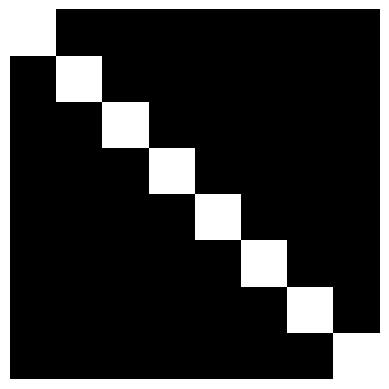

In [5]:
X = np.eye(N)          # Imagen limpia: matriz identidad N x N (diagonal blanca)
x = X.flatten()        # Vector de N² = 64 píxeles (misma forma que el ruido e)

# Volver a N x N solo para visualizar; escala fija 0 = negro, 1 = blanco
plt.imshow(x.reshape(N, N), cmap="gray", vmin=0, vmax=1)
plt.axis("off")        # Sin ejes
plt.show()

### Algoritmo de entrenamiento: denoising score matching

ENTRADA: imágenes originales y niveles de ruido σ

Normalizar las imágenes
Separar datos de entrenamiento y evaluación
Inicializar los parámetros θ del modelo

REPETIR hasta completar el entrenamiento:
    Seleccionar un lote de imágenes originales x
    Seleccionar un nivel de ruido σ

    Generar ruido nuevo: e = σ · Normal(0, I)
    Construir imágenes perturbadas: y = x + e

    Calcular el campo objetivo: S_objetivo = −e / σ²
    Predecir el campo: S_predicho = sθ(y, σ)

    Pérdida = ½ · promedio(||S_predicho − S_objetivo||²)
    Actualizar θ usando el gradiente de la pérdida

Evaluar el modelo con los datos reservados
SALIDA: campo aprendido sθ(y, σ)

### Algoritmo de entrenamiento: denoising score matching

**Entrada:** imágenes originales $\mathbf{x}$ y nivel de ruido $\sigma$.
**Salida:** campo aprendido $\mathbf{s}_\theta(\mathbf{y})$.

---

#### A. Demostración de una vuelta (sin modelo, solo para visualizar)

1. **Generar el ruido:**
$$
\mathbf{Z} \sim \mathcal{N}(\mathbf{0}, I), \qquad \mathbf{e} = \sigma\,\mathbf{Z}
$$
2. **Construir la imagen original** $\mathbf{x}$ (la diagonal de $8\times 8$, aplanada a 64 píxeles).
3. **Calcular el campo objetivo**, que solo depende del ruido:
$$
\mathbf{S}_{\text{objetivo}} = -\frac{\mathbf{e}}{\sigma^2}
$$
4. **Construir la imagen perturbada:**
$$
\mathbf{y} = \mathbf{x} + \mathbf{e}
$$

> El campo objetivo y la imagen perturbada salen del mismo ruido $\mathbf{e}$ y no dependen el uno del otro, por eso el orden entre los pasos 3 y 4 da igual.

---

#### B. Entrenamiento (se repite muchas veces)

0. **Inicializar** los parámetros del modelo: $\theta = (A, \mathbf{B})$ en cero.

**Repetir:**

1. Generar ruido **nuevo**: $\mathbf{e} = \sigma\,\mathbf{Z}$.
2. Imagen perturbada: $\mathbf{y} = \mathbf{x} + \mathbf{e}$.
3. Campo objetivo: $\mathbf{S}_{\text{objetivo}} = -\mathbf{e}/\sigma^2$.
4. Campo predicho por el modelo: $\mathbf{S}_{\text{predicho}} = A\,\mathbf{y} + \mathbf{B}$.
5. Pérdida:
$$
L = \tfrac12\,\big\langle \|\mathbf{S}_{\text{predicho}} - \mathbf{S}_{\text{objetivo}}\|^2 \big\rangle
$$
6. Actualizar $A$ y $\mathbf{B}$ con el gradiente de la pérdida.

Al final, los valores ideales son $A = -1/\sigma^2$ y $\mathbf{B} = \mathbf{x}/\sigma^2$.

---

#### C. Evaluación

Perturbar la imagen con ruido **que el modelo nunca vio** y recuperarla con
$$
\mathbf{x}_{\text{estimada}} = \mathbf{y} + \sigma^2\,\mathbf{s}_\theta(\mathbf{y})
$$
Si $\mathbf{x}_{\text{estimada}} \approx \mathbf{x}$, el modelo aprendió el campo correctamente.

---

> **En este ejemplo de juguete** hay una sola imagen, así que no se normaliza ni se separan datos de entrenamiento y evaluación. Esos pasos aparecen más adelante, con las imágenes de perros y

#### A. Demostración de una vuelta (sin modelo, solo para visualizar)

1. **Construir la imagen original** $\mathbf{x}$ (la diagonal de $8\times 8$, aplanada a 64 píxeles).


2. **Generar el ruido y calcular el campo objetivo:**
$$
\mathbf{Z} \sim \mathcal{N}(\mathbf{0}, I), \qquad \mathbf{e} = \sigma\,\mathbf{Z}, \qquad \mathbf{S}_{\text{objetivo}} = -\frac{\mathbf{e}}{\sigma^2}
$$


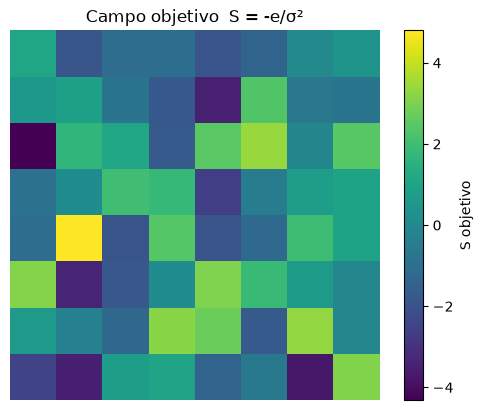

In [9]:
# Campo objetivo (score): dirección para volver de y hacia x
# S_objetivo le dice a cada píxel con ruido hacia dónde moverse, y cuánto, para volver a su valor limpio.
S_objetivo = -e / sigma**2

lim = np.abs(S_objetivo).max()
plt.imshow(S_objetivo.reshape(N, N))
plt.colorbar(label="S objetivo")
plt.title("Campo objetivo  S = -e/σ²")
plt.axis("off")
plt.show()

**¿Cómo leer la imagen del campo objetivo?**

Cada cuadro es un píxel, y su color indica **hacia dónde y cuánto** debe moverse ese píxel para volver a su valor limpio.

| Color | Valor de $S$ | Qué le pasó al píxel | Qué debe hacer |
|---|---|---|---|
| amarillo / verde claro | $S > 0$ | el ruido lo **oscureció** ($e < 0$) | **subir** |
| verde azulado | $S \approx 0$ | casi no recibió ruido | quedarse casi igual |
| azul / morado | $S < 0$ | el ruido lo **aclaró** ($e > 0$) | **bajar** |

Cuanto más intenso el color, mayor fue el ruido y más larga es la "flecha" de corrección.


**Ejemplos de esta imagen:**

- El píxel **amarillo** tiene $S \approx 4.4$. Su ruido fue $e = -\sigma^2 S = -0.25 \cdot 4.4 = -1.1$: quedó $1.1$ más oscuro, así que debe subir $1.1$.
- El píxel **morado más oscuro** tiene $S \approx -3.8$. Su ruido fue $e = -0.25 \cdot (-3.8) = 0.95$: quedó $0.95$ más claro, así que debe

3. **Construir la imagen perturbada:**
$$
\mathbf{y} = \mathbf{x} + \mathbf{e}
$$

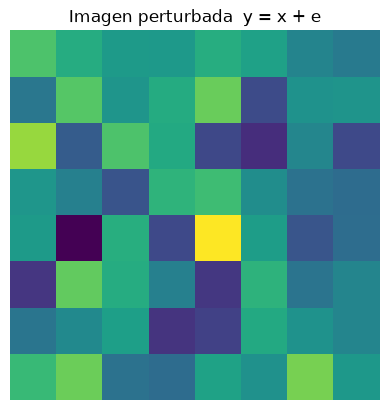

In [12]:
# Imagen perturbada: e ya incluye a sigma, así que NO se multiplica otra vez
y = x + e

plt.imshow(y.reshape(N, N))
plt.title("Imagen perturbada  y = x + e")
plt.axis("off")
plt.show()

**¿Cómo leer la imagen perturbada?**

Es la imagen limpia con ruido sumado píxel por píxel, $\mathbf{y} = \mathbf{x} + \mathbf{e}$:

| Píxel | Limpio $x$ | Ruido $e$ | Perturbado $y$ |
|---|---|---|---|
| de la diagonal | 1 | $+0.3$ | $1.3$ (más claro) |
| de la diagonal | 1 | $-0.6$ | $0.4$ (más oscuro) |
| del fondo | 0 | $+0.5$ | $0.5$ (gris) |
| del fondo | 0 | $-0.2$ | $-0.2$ |



#### B. Entrenamiento (se repite muchas veces)

En esta parte se repite muchas veces la vuelta de la demostración, pero ahora con un modelo que aprende a predecir el campo objetivo.

0. **Inicializar** los parámetros del modelo: $\theta = (A, \mathbf{B})$ en cero.

**Repetir:**

1. Generar ruido **nuevo**: $\mathbf{e} = \sigma\,\mathbf{Z}$, con $\mathbf{Z} \sim \mathcal{N}(\mathbf{0}, I)$.
2. Campo objetivo: $\mathbf{S}_{\text{objetivo}} = -\mathbf{e}/\sigma^2$.
3. Imagen perturbada: $\mathbf{y} = \mathbf{x} + \mathbf{e}$.
4. Campo predicho por el modelo: $\mathbf{S}_{\text{predicho}} = A\,\mathbf{y} + \mathbf{B}$.
5. Pérdida:
$$
L = \tfrac12\,\big\langle \|\mathbf{S}_{\text{predicho}} - \mathbf{S}_{\text{objetivo}}\|^2 \big\rangle
$$
6. Actualizar $A$ y $\mathbf{B}$ con el gradiente de la pérdida.

Al final, los valores ideales son $A = -1/\sigma^2$ y $\mathbf{B} = \mathbf{x}/\sigma^2$.

In [15]:
# Entrenar modelo
sigma = 2                # Nivel de ruido σ
A = 0.0                    # Pendiente del modelo (un solo número)
B = np.zeros_like(x)       # Desplazamiento: un valor por píxel
D = x.size                 # Número de píxeles (64)

alphaA = 0.5               # Tasa de aprendizaje de A
alphaB = 5.0               # Tasa de aprendizaje de B
rng = np.random.default_rng(42)

for i in range(50000):
    # 1. Ruido nuevo e imagen perturbada
    e = rng.normal(0, sigma, size=x.shape)   # e ~ N(0, σ²), ya incluye σ
    y = x + e

    # 2. Campo objetivo y campo predicho
    S_objetivo = -e / sigma**2
    S_predicho = A * y + B

    # 3. Pérdida
    error = S_predicho - S_objetivo
    loss = 0.5 * np.mean(error**2)

    # 4. Descenso de gradiente
    A = A - alphaA * np.mean(error * y)
    B = B - alphaB * error / D

# Resultados
print("Pérdida final:", loss)
print("A aprendido:", A, " (teórico -1/σ² =", -1/sigma**2, ")")
print(f"B aprendido (debe ser {1/sigma**2} en la diagonal y 0 en el resto):")
print(np.round(B.reshape(N, N), 3))


Pérdida final: 9.155876644132196e-18
A aprendido: -0.25000000087281626  (teórico -1/σ² = -0.25 )
B aprendido (debe ser 0.25 en la diagonal y 0 en el resto):
[[ 0.25 -0.   -0.    0.   -0.    0.   -0.    0.  ]
 [-0.    0.25  0.   -0.    0.   -0.   -0.   -0.  ]
 [-0.    0.    0.25  0.    0.   -0.   -0.    0.  ]
 [-0.   -0.   -0.    0.25 -0.    0.    0.   -0.  ]
 [ 0.    0.   -0.    0.    0.25 -0.   -0.   -0.  ]
 [-0.   -0.    0.   -0.   -0.    0.25 -0.   -0.  ]
 [ 0.    0.    0.    0.    0.   -0.    0.25  0.  ]
 [-0.    0.   -0.    0.    0.   -0.    0.    0.25]]


### Recuperar la imagen con el modelo entrenado

Si el modelo aprendió bien, $\mathbf{S}_{\text{predicho}} \approx \mathbf{S}_{\text{objetivo}} = -\dfrac{\mathbf{y} - \mathbf{x}}{\sigma^2}$. Despejando $\mathbf{x}$:
$$
\mathbf{x}_{\text{estimada}} = \mathbf{y} + \sigma^2\,\mathbf{S}_{\text{predicho}}
$$

Es **un solo salto**: el campo da la dirección para cada píxel y $\sigma^2$ el tamaño del paso.


**Nota:** aquí se usa la imagen ruidosa de la **última vuelta del entrenamiento**, así que el modelo ya la "vio". La prueba real viene después, con ruido nuevo que el modelo nunca vio.

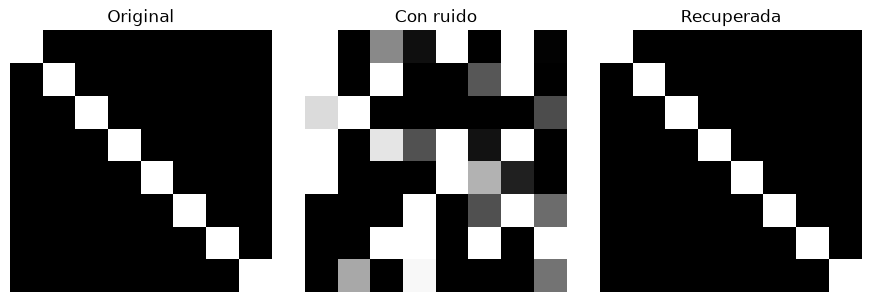

¿Recuperó x? False


In [17]:
# Se usa la imagen ruidosa de la última iteración del entrenamiento
x_estimada = y + sigma**2 * S_predicho

fig, ejes = plt.subplots(1, 3, figsize=(9, 3))
for eje, (img, titulo) in zip(ejes, [(x, "Original"), (y, "Con ruido"), (x_estimada, "Recuperada")]):
    eje.imshow(img.reshape(N, N), cmap="gray", vmin=0, vmax=1)
    eje.set_title(titulo)
    eje.axis("off")
plt.tight_layout()
plt.show()

print("¿Recuperó x?", np.allclose(x_estimada, x))   # True

#### C. Evaluación: recuperar una imagen con ruido nuevo

Se prueba el modelo con un ruido que **nunca vio** durante el entrenamiento, usando otra semilla (`123` en vez de `42`). Los parámetros $A$ y $\mathbf{B}$ quedan fijos: ya no se actualizan.

1. **Perturbar la imagen original con ruido nuevo:**
$$
\mathbf{e}_{\text{prueba}} \sim \mathcal{N}(\mathbf{0}, \sigma^2 I), \qquad \mathbf{y}_{\text{prueba}} = \mathbf{x} + \mathbf{e}_{\text{prueba}}
$$

2. **Evaluar el campo con el modelo entrenado:**
$$
\mathbf{S}_{\text{prueba}} = A\,\mathbf{y}_{\text{prueba}} + \mathbf{B}
$$

3. **Recuperar la imagen** (un solo salto):
$$
\mathbf{x}_{\text{recuperada}} = \mathbf{y}_{\text{prueba}} + \sigma^2\,\mathbf{S}_{\text{prueba}}
$$

4. **Medir el error** con el error cuadrático medio (MSE) respecto a la imagen original:
$$
\text{MSE} = \frac{1}{D}\sum_{i=1}^{D}\big(\text{imagen}_i - x_i\big)^2
$$
   - **Con ruido:** $\text{MSE}(\mathbf{y}_{\text{prueba}}, \mathbf{x}) \approx \sigma^2 = 4$, porque la diferencia es justo el ruido.
   - **Recuperada:** $\text{MSE}(\mathbf{x}_{\text{recuperada}}, \mathbf{x}) \approx 0$ si el modelo aprendió bien.

5. **Visualizar** la imagen original

ENTRADA: imagen perturbada y, nivel de ruido σ,
         campo aprendido sθ

Calcular el campo: S = sθ(y, σ)

Estimar la imagen limpia:
    x_estimada = y + σ² · S

Si conocemos la imagen original:
    Comparar la estimación con ella
    Calcular el error de recuperación

SALIDA: imagen limpia estimada

MSE con ruido:   3.453027835372964
MSE recuperada:  2.3492311654847175e-16
¿Recuperó x? True


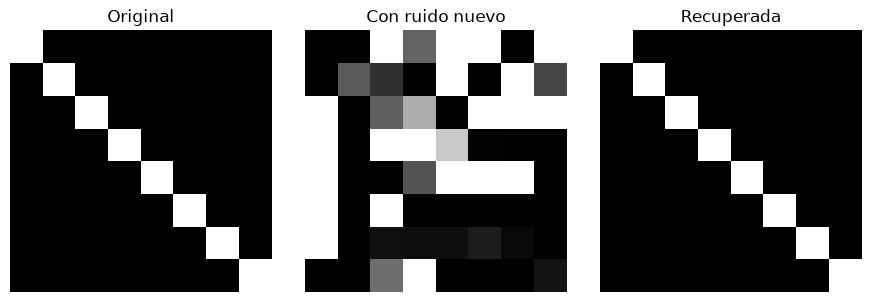

In [18]:
# Prueba con ruido NUEVO (el modelo nunca lo vio)
rng_prueba = np.random.default_rng(123)    # Semilla distinta a la del entrenamiento

# 1. Perturbar la imagen original con ruido nuevo
e_prueba = rng_prueba.normal(0, sigma, size=x.shape)   # Ya incluye σ
y_prueba = x + e_prueba

# 2. Evaluar el campo con A y B ya entrenados (no se actualizan)
S_prueba = A * y_prueba + B

# 3. Recuperar la imagen
x_recuperada = y_prueba + sigma**2 * S_prueba

# 4. Medir el error
print("MSE con ruido:  ", np.mean((y_prueba - x)**2))      # ≈ σ²
print("MSE recuperada: ", np.mean((x_recuperada - x)**2))  # ≈ 0
print("¿Recuperó x?", np.allclose(x_recuperada, x, atol=1e-3))

# 5. Visualizar
fig, ejes = plt.subplots(1, 3, figsize=(9, 3))
for eje, (img, titulo) in zip(ejes, [(x, "Original"), (y_prueba, "Con ruido nuevo"), (x_recuperada, "Recuperada")]):
    eje.imshow(img.reshape(N, N), cmap="gray", vmin=0, vmax=1)
    eje.set_title(titulo)
    eje.axis("off")
plt.tight_layout()
plt.show()

#### D. Generar con Langevin

Ahora el modelo entrenado se usa para **generar** una imagen, partiendo de ruido puro y **sin usar la imagen original**. ¿Puede el modelo crear una imagen desde cero, sin que se le muestre ninguna?

1. **Inicializar con ruido puro:**
$$
\mathbf{Y}_0 \sim \mathcal{N}(\mathbf{0}, I)
$$

2. **Repetir $n$ pasos de Langevin** con el campo aprendido:
$$
\mathbf{S} = A\,\mathbf{Y}_n + \mathbf{B}, \qquad
\mathbf{Y}_{n+1} = \mathbf{Y}_n + \Delta t\,\mathbf{S} + \sqrt{2\,\Delta t}\;\mathbf{Z}_n, \quad \mathbf{Z}_n \sim \mathcal{N}(\mathbf{0}, I)
$$

3. **Recuperación final** (un solo salto, como en la evaluación):
$$
\mathbf{Y}_{\text{recuperada}} = \mathbf{Y} + \sigma^2\,(A\,\mathbf{Y} + \mathbf{B})
$$

El modelo aprendió el score de las imágenes **con ruido**, $\mathcal{N}(\mathbf{x}, \sigma^2 I)$. Por eso Langevin lleva a imágenes "probables, pero con ruido de tamaño $\sigma$". El salto final quita ese ruido.

$$
\text{ruido puro} \xrightarrow{\text{Langevin}} \text{imagen probable con ruido} \xrightarrow{\text{salto}} \text{imagen limpia}
$$

**Visualización:** inicialización aleatoria → después de Langevin → recuperación final.



# Langevine

ENTRADA: campo aprendido, niveles σ de mayor a menor,
         número de pasos K y constante pequeña c

Inicializar desde ruido:
    Y = μ + σ_max · Normal(0, I)
    μ es la media de las imágenes de entrenamiento

PARA cada nivel σ, desde σ_max hasta σ_min:
    Elegir el paso: h = c · σ²

    REPETIR K veces:
        Calcular el campo: S = sθ(Y, σ)
        Generar ruido nuevo: Z = Normal(0, I)

        Actualizar mediante Langevin:
            Y = Y + h · S + √(2h) · Z

Opcionalmente aplicar la recuperación final:
    Y = Y + σ_min² · sθ(Y, σ_min)

SALIDA: imagen generada

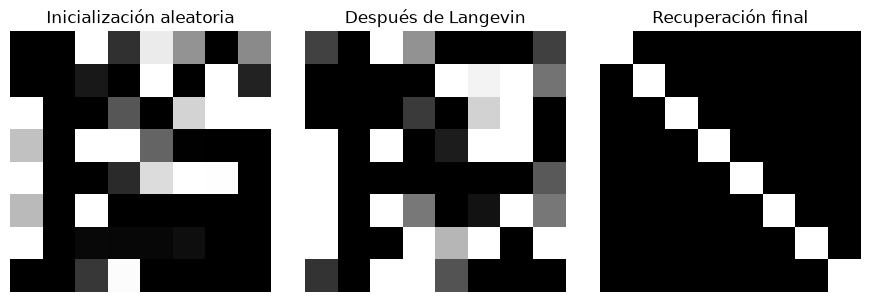

In [19]:
rng_generacion = np.random.default_rng(123)

# Inicialización independiente de la imagen original.
Y = rng_generacion.normal(0, 1, size=x.shape)
Y_inicial = Y.copy()

dt = 0.001  # Para sigma = 0.1 y A cercano a -100.
n_pasos = 1000

# Aquí entra Langevin.
for paso in range(n_pasos):

    S = A * Y + B
    Z = rng_generacion.normal(size=Y.shape)
    Y = Y + dt * S + np.sqrt(2 * dt) * Z

# Recuperación final: es una operación distinta.
Y_recuperada = Y + sigma**2 * (A * Y + B)

fig, ejes = plt.subplots(1, 3, figsize=(9, 3))

comparaciones = [
    (Y_inicial, "Inicialización aleatoria"),
    (Y, "Después de Langevin"),
    (Y_recuperada, "Recuperación final")
]

for eje, (imagen, titulo) in zip(ejes, comparaciones):
    eje.imshow(
        np.clip(imagen.reshape(N, N), 0, 1),
        cmap="gray", vmin=0, vmax=1
    )
    eje.set_title(titulo)
    eje.axis("off")

plt.tight_layout()
plt.show()

**¿Cómo leer esta figura?**

| Panel | Qué es | Qué se ve |
|---|---|---|
| **Inicialización aleatoria** | $\mathbf{Y}_0 \sim \mathcal{N}(\mathbf{0}, I)$: ruido puro | píxeles al azar, sin ninguna estructura |
| **Después de Langevin** | $\mathbf{Y}_{\text{final}}$, tras 1000 pasos con $\Delta t = 0.001$ | todavía muy ruidosa: **la diagonal no se distingue** |
| **Recuperación final** | $\mathbf{Y}_{\text{final}} + \sigma^2(A\,\mathbf{Y}_{\text{final}} + \mathbf{B})$ | la diagonal limpia, perfecta |



Se puede apreciar que después de Langevin la imagen sigue muy ruidosa, esto es debido a que se simuló muy poco tiempo. 
L a figura muestra entonces el procedimiento completo (ruido → Langevin → recuperación), pero en este ejemplo, Langevin casi no contribuye. Para ver su efecto, habría que simular más tiempo, por ejemplo `dt = 0.01` y `n_pasos = 2000` ($t = 20$).

# Parte 2: Caso con muchas imágenes — perros de CIFAR-10

Ahora se repite el mismo procedimiento, pero con 1000 imágenes distintas de perros, para que el modelo tenga que aprender qué tienen en común.

El procedimiento es el mismo:

1. Añadir ruido a las imágenes: $\mathbf{y} = \mathbf{x} + \mathbf{e}$.
2. Calcular el campo objetivo: $\mathbf{S}_{\text{objetivo}} = -\mathbf{e}/\sigma^2$.
3. Entrenar un modelo lineal $\mathbf{s} = a\,\mathbf{Y} + \mathbf{B}$ para que lo prediga.
4. Usarlo para limpiar imágenes y para generar con Langevin.

**Diferencias con la parte 1:**

| | Parte 1 | Parte 2 |
|---|---|---|
| Imágenes | 1 (diagonal) | 1000 (perros) |
| Tamaño | $8\times8$, blanco y negro | $32\times32$, a color (RGB) |
| Valores por imagen | 64 | $32 \times 32 \times 3 = 3072$ |
| Separar entrenamiento y evaluación | no | sí (80 % / 20 %) |
| Entrenamiento | siempre la misma imagen | lotes de 32 imágenes al azar |

### Cargar las imágenes de perros

Se usa **CIFAR-10**, un conjunto de 50 000 imágenes pequeñas ($32 \times 32$ píxeles, a color) de 10 clases: avión, auto, pájaro, gato, venado, **perro**, rana, caballo, barco y camión. Cada imagen tiene una etiqueta del 0 al 9, y los perros son la **etiqueta 5**.

- `load_dataset(..., streaming=True)` lee las imágenes **una por una** desde internet, sin descargar el conjunto completo.
- El `for` recorre las imágenes y se queda solo con las de etiqueta 5.
- `.convert("RGB")` asegura que cada imagen tenga 3 canales de color (rojo, verde, azul).
- `np.array(...)` convierte cada imagen en un arreglo de forma $(32, 32, 3)$, con valores enteros entre 0 y 255.
- Cada 25 perros se imprime el avance, y al llegar a 1000 se detiene con `break`.

In [20]:
%pip -q install datasets

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:
import numpy as np
import matplotlib.pyplot as plt
from datasets import load_dataset

datos = load_dataset(
    "uoft-cs/cifar10",
    split="train",
    streaming=True
)
perros = []

for ejemplo in datos:
    if ejemplo["label"] == 5:  # Perro
        perros.append(np.array(ejemplo["img"].convert("RGB")))

        if len(perros) % 25 == 0:
            print(f"Cargados: {len(perros)} perros")

        if len(perros) == 1000:
            break


c:\CCA\005_CCA_Estudiantes\Laboratorios\01_LabPatronesAgente\Tools\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\CCA\005_CCA_Estudiantes\Laboratorios\01_LabPatronesAgente\Tools\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\valen\.cache\huggingface\hub\datasets--uoft-cs--cifar10. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Develope

Cargados: 25 perros
Cargados: 50 perros
Cargados: 75 perros
Cargados: 100 perros
Cargados: 125 perros
Cargados: 150 perros
Cargados: 175 perros
Cargados: 200 perros
Cargados: 225 perros
Cargados: 250 perros
Cargados: 275 perros
Cargados: 300 perros
Cargados: 325 perros
Cargados: 350 perros
Cargados: 375 perros
Cargados: 400 perros
Cargados: 425 perros
Cargados: 450 perros
Cargados: 475 perros
Cargados: 500 perros
Cargados: 525 perros
Cargados: 550 perros
Cargados: 575 perros
Cargados: 600 perros
Cargados: 625 perros
Cargados: 650 perros
Cargados: 675 perros
Cargados: 700 perros
Cargados: 725 perros
Cargados: 750 perros
Cargados: 775 perros
Cargados: 800 perros
Cargados: 825 perros
Cargados: 850 perros
Cargados: 875 perros
Cargados: 900 perros
Cargados: 925 perros
Cargados: 950 perros
Cargados: 975 perros
Cargados: 1000 perros


### Juntar las imágenes y visualizar algunas

`np.stack(perros)` convierte la lista de 1000 imágenes en **un solo arreglo** de cuatro dimensiones:
$$
\texttt{X\_perros.shape} = (1000,\ 32,\ 32,\ 3)
$$

| Dimensión | Tamaño | Significado |
|---|---|---|
| 1ª | 1000 | número de imágenes |
| 2ª | 32 | filas (alto) |
| 3ª | 32 | columnas (ancho) |
| 4ª | 3 | canales de color: rojo, verde, azul |

Así se puede operar con todas las imágenes a la vez, por ejemplo sumarles ruido en una sola línea.

Luego se muestran las primeras 16 imágenes en una cuadrícula de $4 \times 4$.

Forma: (1000, 32, 32, 3)


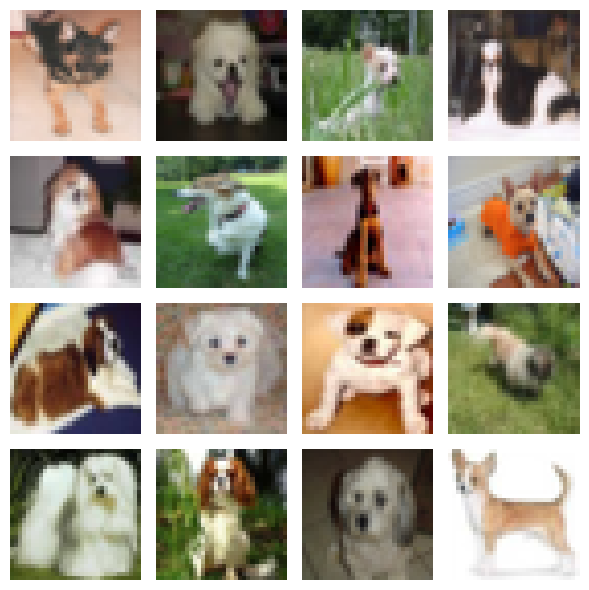

In [22]:
X_perros = np.stack(perros)
print("Forma:", X_perros.shape)

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for ax, imagen in zip(axes.ravel(), X_perros[:16]):
    ax.imshow(imagen)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Normalizar las imágenes

Los píxeles originales son enteros entre 0 y 255. Se llevan al intervalo $[-1, 1]$:
$$
x_{\text{normalizado}} = \frac{x}{127.5} - 1
$$



Se debe normalizar para:

- **Para ajustar el ruido** Con $\sigma = 0.3$, un ruido de $\pm 0.3$ es una mancha moderada en una escala de $[-1, 1]$. En la escala $[0, 255]$ sería prácticamente invisible.
- **Para centrar los datos en 0.** El modelo lineal $a\,\mathbf{Y} + \mathbf{B}$ y el ruido $\mathcal{N}(0, \sigma^2)$ están centrados en 0, así que conviene que las imágenes también lo estén.
- **Para entrenar mejor.** Los valores pequeños y centrados evitan gradientes enormes y hacen que el aprendizaje sea más estable.


In [23]:
X_entrenamiento = X_perros.astype(np.float32) / 127.5 - 1.0

### Perturbar las imágenes y calcular el campo objetivo

Se genera ruido gaussiano independiente para cada imagen, cada píxel y cada canal de color:
$$
\boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0},\ \sigma^2 I), \qquad \sigma = 0.3
$$

Con él se construyen las imágenes perturbadas y el campo objetivo:
$$
\mathbf{Y} = \mathbf{X} + \boldsymbol{\epsilon}, \qquad \mathbf{S}_{\text{objetivo}} = -\frac{\boldsymbol{\epsilon}}{\sigma^2}
$$

Los tres arreglos tienen la misma forma que las imágenes limpias:
$$
(1000,\ 32,\ 32,\ 3)
$$
es decir, $1000 \times 32 \times 32 \times 3 = 3\,072\,000$ valores de ruido, cada uno distinto.

**Diferencias con la parte 1:**
- `rng.normal(loc=0, scale=sigma, ...)` genera el ruido **ya multiplicado por $\sigma$**. Equivale a $\sigma\,\mathbf{Z}$, con $\mathbf{Z} \sim \mathcal{N}(\mathbf{0}, I)$.
- $\sigma = 0.3$ es un ruido moderado en la escala $[-1, 1]$.
- `.astype(np.float32)` usa la misma precisión que las imágenes, para ahorrar memoria.

In [24]:
rng = np.random.default_rng(42)
sigma = 0.3

# Ruido independiente para cada imagen, píxel y canal
epsilon = rng.normal(
    loc=0,
    scale=sigma,
    size=X_entrenamiento.shape
).astype(np.float32)

X_ruidosas = X_entrenamiento + epsilon

# Campo objetivo para entrenar
S_objetivo = -epsilon / sigma**2

print("Imágenes limpias:", X_entrenamiento.shape)
print("Imágenes ruidosas:", X_ruidosas.shape)
print("Score objetivo:", S_objetivo.shape)

Imágenes limpias: (1000, 32, 32, 3)
Imágenes ruidosas: (1000, 32, 32, 3)
Score objetivo: (1000, 32, 32, 3)


### Visualizar el ruido canal por canal

Se toma la primera imagen ($i = 0$) y se separa en sus tres canales de color. La figura es una cuadrícula de $3 \times 3$:

| | Columna 1: limpio | Columna 2: ruido | Columna 3: con ruido |
|---|---|---|---|
| **Fila 1: Rojo** | canal rojo de $\mathbf{x}$ | $\epsilon$ del canal rojo | canal rojo de $\mathbf{y}$ |
| **Fila 2: Verde** | canal verde de $\mathbf{x}$ | $\epsilon$ del canal verde | canal verde de $\mathbf{y}$ |
| **Fila 3: Azul** | canal azul de $\mathbf{x}$ | $\epsilon$ del canal azul | canal azul de $\mathbf{y}$ |

Cada fila muestra la misma relación de siempre: **limpio + ruido = con ruido**.

**El ruido (columna del medio)** se dibuja con una paleta de dos colores centrada en 0:
- **rojo:** ruido positivo (el canal se intensifica),
- **azul:** ruido negativo (el canal se apaga),
- **blanco:** casi sin ruido.

La escala va de $-3\sigma$ a $3\sigma$, es decir, de $-0.9$ a $0.9$, que cubre casi todos los valores posibles del ruido.



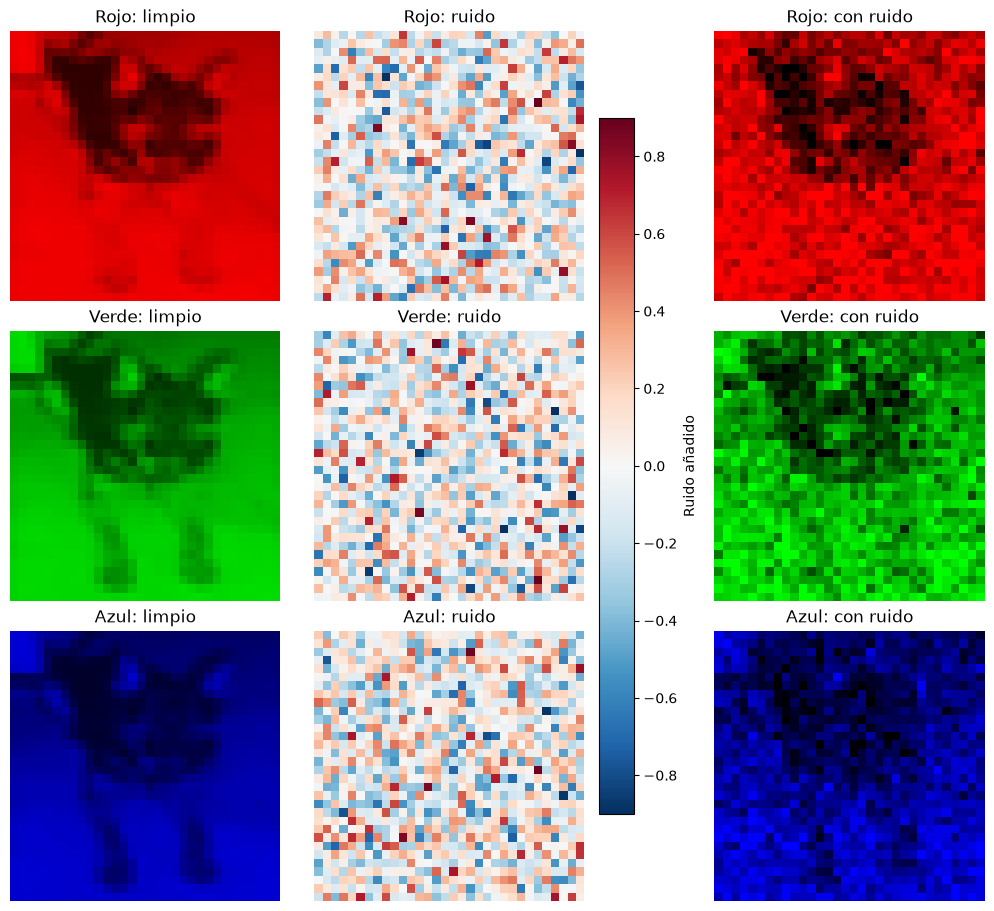

In [25]:
i = 0
limpia = np.clip((X_entrenamiento[i] + 1) / 2, 0, 1)
ruidosa = np.clip((X_ruidosas[i] + 1) / 2, 0, 1)

nombres = ["Rojo", "Verde", "Azul"]

fig, axes = plt.subplots(
    3, 3, figsize=(10, 9), constrained_layout=True
)

for canal, nombre in enumerate(nombres):

    # Mostrar únicamente este canal en su color
    limpia_canal = np.zeros_like(limpia)
    limpia_canal[:, :, canal] = limpia[:, :, canal]

    ruidosa_canal = np.zeros_like(ruidosa)
    ruidosa_canal[:, :, canal] = ruidosa[:, :, canal]

    axes[canal, 0].imshow(limpia_canal)
    axes[canal, 0].set_title(f"{nombre}: limpio")

    im = axes[canal, 1].imshow(
        epsilon[i, :, :, canal],
        cmap="RdBu_r",
        vmin=-3 * sigma,
        vmax=3 * sigma
    )
    axes[canal, 1].set_title(f"{nombre}: ruido")

    axes[canal, 2].imshow(ruidosa_canal)
    axes[canal, 2].set_title(f"{nombre}: con ruido")

for ax in axes.ravel():
    ax.axis("off")

fig.colorbar(
    im,
    ax=axes[:, 1].tolist(),
    shrink=0.8,
    label="Ruido añadido"
)

plt.show()

### Imagen completa: limpia y con ruido

Se muestra la primera imagen ($i = 0$) con sus tres canales combinados, sin ruido y con ruido:
$$
\mathbf{x} \qquad \text{vs.} \qquad \mathbf{y} = \mathbf{x} + \boldsymbol{\epsilon}
$$


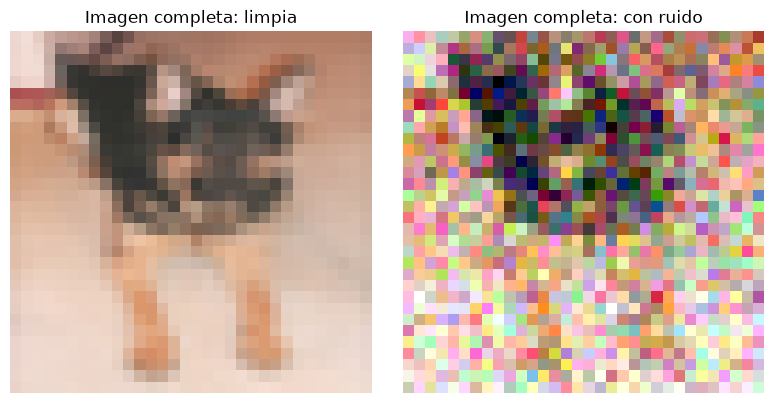

In [26]:
i = 0
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(
    np.clip((X_entrenamiento[i] + 1) / 2, 0, 1)
)
axes[0].set_title("Imagen completa: limpia")
axes[1].imshow(
    np.clip((X_ruidosas[i] + 1) / 2, 0, 1)
)
axes[1].set_title("Imagen completa: con ruido")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Se observa que el perro todavía se reconoce, pero la imagen queda cubierta de granos de colores. Como cada canal recibió un ruido distinto, cada grano cambia también el tono del píxel, no solo su brillo.

### Separar los datos y preparar el modelo

**1. Separar entrenamiento y evaluación (80 % / 20 %)**

| Conjunto | Imágenes | Para qué |
|---|---|---|
| `datos` | las primeras 800 | entrenar el modelo |
| `evaluacion` | las últimas 200 | probarlo con imágenes que **nunca vio** |

**2.** Se usa un modelo lineal :
$$
\mathbf{S}_{\text{predicho}} = a\,\mathbf{Y} + \mathbf{B}
$$

| Parámetro | Qué es | Forma | Valor inicial |
|---|---|---|---|
| $a$ | un solo número, igual para todos los valores | escalar | 0 |
| $\mathbf{B}$ | un valor por píxel y canal | $(32, 32, 3)$ | 0 |

El número de componentes de cada imagen es
$$
D = 32 \times 32 \times 3 = 3072
$$

**3. Tasas de aprendizaje**
$$
\text{lr}_a = 0.01, \qquad \text{lr}_B = \text{lr}_a \cdot D = 0.01 \cdot 3072 = 30.72
$$


In [36]:
# X_entrenamiento ya debe estar normalizado a [-1, 1]
corte = int(0.8 * len(X_entrenamiento))
datos = X_entrenamiento[:corte]
evaluacion = X_entrenamiento[corte:]

# Parámetros iniciales
a = 0.0
B = np.zeros_like(datos[0])

D = B.size  # Número de componentes: píxeles × canales

lr_a = 0.01
lr_B = lr_a * D  # Compensa el promedio sobre D componentes

### Entrenamiento con lotes de imágenes

Se repiten 2000 pasos. En cada paso:

1. **Elegir un lote** de 32 imágenes al azar del conjunto de entrenamiento:
$$
\mathbf{X} \in \mathbb{R}^{32 \times 32 \times 32 \times 3}
$$
2. **Ruido nuevo** e imágenes perturbadas:
$$
\boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0}, \sigma^2 I), \qquad \mathbf{Y} = \mathbf{X} + \boldsymbol{\epsilon}
$$
3. **Campo objetivo y campo predicho:**
$$
\mathbf{S}_{\text{objetivo}} = -\frac{\boldsymbol{\epsilon}}{\sigma^2}, \qquad \mathbf{S}_{\text{predicho}} = a\,\mathbf{Y} + \mathbf{B}
$$
4. **Pérdida:** promedio del error al cuadrado sobre las 32 imágenes y sus 3072 componentes,
$$
L = \tfrac12\,\big\langle (\mathbf{S}_{\text{predicho}} - \mathbf{S}_{\text{objetivo}})^2 \big\rangle
$$
5. **Gradientes y actualización:**
$$
\frac{\partial L}{\partial a} = \langle \text{error} \cdot \mathbf{Y} \rangle, \qquad
\frac{\partial L}{\partial \mathbf{B}} = \frac{1}{D}\,\langle \text{error} \rangle_{\text{lote}}
$$
$$
a \leftarrow a - \text{lr}_a\,\frac{\partial L}{\partial a}, \qquad \mathbf{B} \leftarrow \mathbf{B} - \text{lr}_B\,\frac{\partial L}{\partial \mathbf{B}}
$$

La pérdida de cada paso se guarda en `historia` para graficar cómo evoluciona.

Paso 200: pérdida = 4.4999
Paso 400: pérdida = 4.2034
Paso 600: pérdida = 3.9616
Paso 800: pérdida = 4.0312
Paso 1000: pérdida = 4.0654
Paso 1200: pérdida = 4.0849
Paso 1400: pérdida = 4.0723
Paso 1600: pérdida = 4.1427
Paso 1800: pérdida = 4.1864
Paso 2000: pérdida = 3.9837
a aprendido: -3.0484605


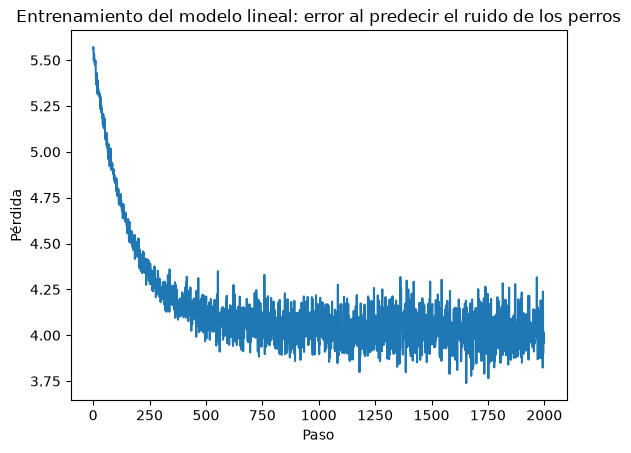

In [37]:
n_pasos = 2000
historia = []
for paso in range(n_pasos):
    # Seleccionar un grupo de imágenes
    indices = rng.integers(0, len(datos), size=32)
    X = datos[indices]
    # Agregar ruido nuevo
    epsilon = rng.normal(0, sigma, size=X.shape).astype(np.float32)
    Y = X + epsilon
    # Score objetivo y score predicho
    S_objetivo = -epsilon / sigma**2

    S_predicho = a * Y + B



    error = S_predicho - S_objetivo
    loss = 0.5 * np.mean(error**2)
    # Gradientes de esa pérdida
    grad_a = np.mean(error * Y)
    grad_B = np.mean(error, axis=0) / D

    # Actualizar los parámetros
    a -= lr_a * grad_a
    B -= lr_B * grad_B

    historia.append(loss)

    if (paso + 1) % 200 == 0:
        print(f"Paso {paso + 1}: pérdida = {loss:.4f}")

print("a aprendido:", a)

#plt.title("Entrenamiento del modelo lineal: error al predecir el ruido de los perros\n"
#          r"$L = \frac{1}{2}\langle (a\,\mathbf{Y} + \mathbf{B} + \boldsymbol{\epsilon}/\sigma^2)^2 \rangle$,"
#          f"  σ = {sigma}, lotes de 32 imágenes")

plt.plot(historia)
plt.title("Entrenamiento del modelo lineal: error al predecir el ruido de los perros")
plt.xlabel("Paso")
plt.ylabel("Pérdida")
plt.show()




Al inicio, con $a = 0$ y $\mathbf{B} = 0$ la pérdida vale aproximadamente 5.6, que coincide con el valor teórico $\tfrac12 \cdot \tfrac{1}{\sigma^2} = \tfrac12 \cdot 11.1$. Durante los primeros 500 pasos la pérdida baja rápidamente, mientras el modelo ajusta $a$ y va guardando en $\mathbf{B}$ la imagen promedio de los perros. A partir de ahí se estabiliza alrededor de 4.0 y deja de bajar: no llega a cero porque el modelo lineal no puede saber cuál de los 800 perros había debajo del ruido, y solo es capaz de aprender el perro promedio. Aún se observan muchas oscilaciones debido a que cada paso usa un lote distinto de 32 imágenes y un ruido nuevo, por lo que la pérdida fluctúa alrededor de ese valor mínimo.

### Evaluación: limpiar un perro que el modelo nunca vio

Se toma una imagen del conjunto de **evaluación**, se le agrega ruido nuevo y se recupera con:
$$
\mathbf{Y} = \mathbf{X} + \boldsymbol{\epsilon}, \qquad
\mathbf{X}_{\text{recuperada}} = \mathbf{Y} + \sigma^2\,(a\,\mathbf{Y} + \mathbf{B})
$$

Se comparan la original, la imagen con ruido y la recuperada, y se mide el error con el MSE:

- **MSE con ruido** $\approx \sigma^2 = 0.09$: es el tamaño del ruido.
- **MSE recuperada:** mide cuánto ruido logró quitar el modelo.


Lo que realmente hace el modelo es una **mezcla** de la imagen con ruido (≈ 70 %) y el perro promedio $\boldsymbol{\mu}$ (≈ 30 %). Quita parte del ruido, pero también lleva la imagen hacia el promedio. Por eso la recuperación queda más suave y deslavada, y el error baja pero no llega a 0.
$$
\mathbf{X}_{\text{recuperada}} = \underbrace{(1 + \sigma^2 a)}_{\approx\, 0.7}\,\mathbf{Y} \;+\; \underbrace{\sigma^2\,\mathbf{B}}_{\approx\, 0.3\,\boldsymbol{\mu}}
$$


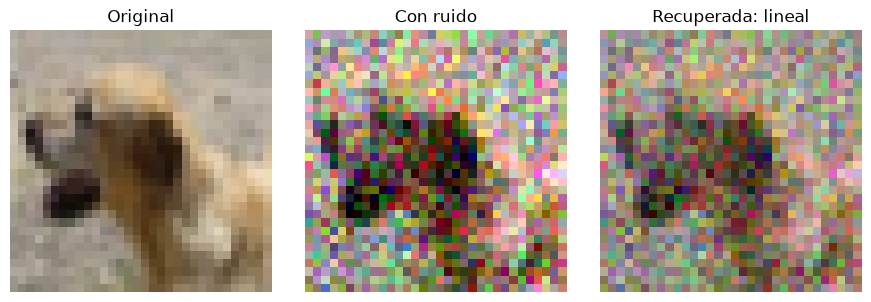

MSE con ruido: 0.09046825
MSE recuperada: 0.05951291


In [38]:
X = evaluacion[4]

epsilon = rng.normal(
    0, sigma, size=X.shape
).astype(np.float32)

Y = X + epsilon

S_predicho = a * Y + B
X_recuperada = Y + sigma**2 * S_predicho

fig, axes = plt.subplots(1, 3, figsize=(9, 3))

imagenes = [X, Y, X_recuperada]
titulos = ["Original", "Con ruido", "Recuperada: lineal"]

for ax, imagen, titulo in zip(axes, imagenes, titulos):
    ax.imshow(np.clip((imagen + 1) / 2, 0, 1))
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("MSE con ruido:", np.mean((Y - X)**2))
print("MSE recuperada:", np.mean((X_recuperada - X)**2))

### Generar con Langevin usando el modelo lineal

Se generan 4 imágenes partiendo de **ruido puro**, sin usar ningún perro:
$$
\mathbf{Y}_0 \sim \mathcal{N}(\mathbf{0}, I)
$$
y se aplican 1000 pasos de Langevin con el campo aprendido:
$$
\mathbf{S} = a\,\mathbf{Y}_n + \mathbf{B}, \qquad
\mathbf{Y}_{n+1} = \mathbf{Y}_n + \Delta t\,\mathbf{S} + \sqrt{2\,\Delta t}\;\mathbf{Z}_n
$$


**Tamaño del paso.** El campo tarda un tiempo del orden de $1/|a|$ en llevar los valores a su sitio, así que el paso se elige como una fracción pequeña de ese tiempo:
$$
\Delta t = \frac{0.05}{|a|}
$$


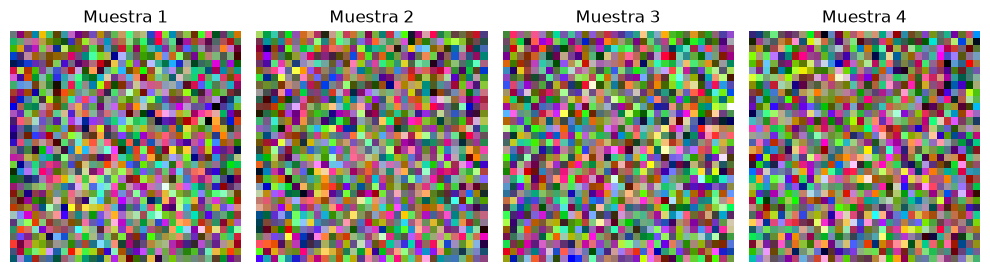

In [39]:
rng = np.random.default_rng(123)

if a >= 0:
    raise ValueError("Necesitamos a < 0 para tener una distribución estable.")

# Cuatro imágenes inicializadas con ruido puro
Y = rng.normal(size=(4,) + B.shape).astype(np.float32)

dt = 0.05 / abs(a)  # Paso pequeño respecto a la escala del campo

for paso in range(1000):
    S = a * Y + B
    Z = rng.normal(size=Y.shape)
    Y = Y + dt * S + np.sqrt(2 * dt) * Z

fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for i, ax in enumerate(axes):
    ax.imshow(np.clip((Y[i] + 1) / 2, 0, 1))
    ax.set_title(f"Muestra {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### Comprobar Langevin: promedio de muchas muestras

Se generan 200 imágenes con Langevin, igual que antes, y se comparan dos cosas:

1. **El promedio de las 200 muestras:**
$$
\bar{\mathbf{Y}} = \frac{1}{200}\sum_{k=1}^{200} \mathbf{Y}^{(k)}
$$
2. **La media que predice el modelo:** como el campo $a\,\mathbf{Y} + \mathbf{B}$ se anula en $\mathbf{Y} = -\mathbf{B}/a$, ese es el centro hacia donde Langevin empuja todo:
$$
\boldsymbol{\mu}_{\text{modelo}} = -\frac{\mathbf{B}}{a}
$$

Si Langevin funciona correctamente, $\bar{\mathbf{Y}} \approx \boldsymbol{\mu}_{\text{modelo}}$. Además, $\boldsymbol{\mu}_{\text{modelo}}$ debería parecerse al **perro promedio** del conjunto de entrenamiento.

In [40]:
rng = np.random.default_rng(123)

if a >= 0:
    raise ValueError("Necesitamos a < 0.")

n_muestras = 200

Y = rng.normal(
    size=(n_muestras,) + B.shape
).astype(np.float32)

dt = 0.05 / abs(a)

for paso in range(1000):
    S = a * Y + B
    Z = rng.normal(size=Y.shape).astype(np.float32)

    Y = Y + dt * S + np.sqrt(2 * dt) * Z
# Promedio de las muestras, sin recortar sus valores
promedio = Y.mean(axis=0)
# Promedio esperado del modelo lineal
media_modelo = -B / a

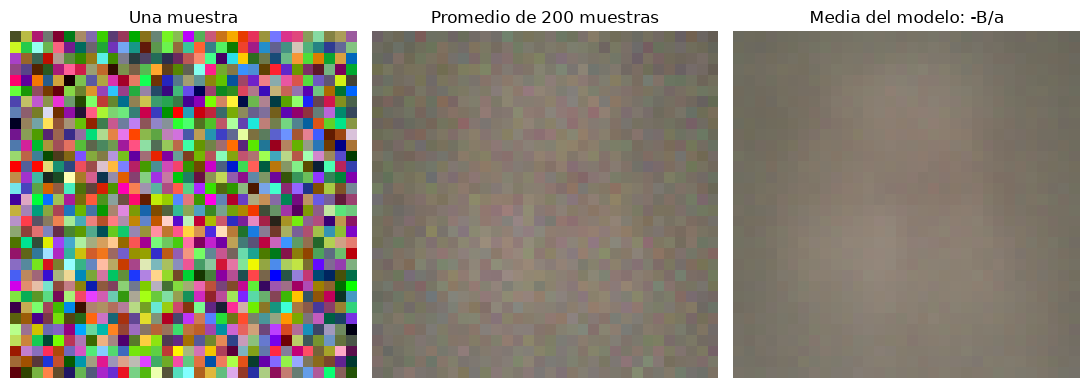

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4))

imagenes = [Y[0], promedio, media_modelo]
titulos = [
    "Una muestra",
    f"Promedio de {n_muestras} muestras",
    "Media del modelo: -B/a"
]

for ax, imagen, titulo in zip(axes, imagenes, titulos):
    ax.imshow(np.clip((imagen + 1) / 2, 0, 1))
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()

La primera imagen, muestra una de las 200 imágenes generadas por Langevin, se muestra sin ninguna estructura reconocible. Cada valor de cada píxel y canal fluctúa por su cuenta alrededor de su centro con una desviación de aproximadamente $1/\sqrt{|a|}$, que es muy grande en la escala $[-1, 1]$, así que el ruido domina por completo la imagen.

Por otro lado, la segunda imagen muestra el promedio de las 200 imágenes generadas. Al promediar, las fluctuaciones aleatorias de cada muestra se cancelan entre sí y queda solo el centro de la distribución. Podría decirse que Langevin funciona bien, pero solo puede generar lo que el modelo lineal aprendió. Un modelo lineal solo aprende el promedio, y el promedio de muchos perros no es un perro.

Finalmente, la última imagen representa la media del modelo. Es prácticamente igual al promedio, pero más suave, porque se calcula directamente sin ruido. Muestra un tono gris café con una zona central un poco más clara, que corresponde a la región donde suele aparecer el perro en las fotos.

De manera general se podría decir que:

1. **Langevin funciona correctamente.** El promedio de las 200 imágenes generadas coincide con la media del modelo, $-\mathbf{B}/a$. Es decir, Langevin lleva las muestras exactamente hacia donde le indica el modelo, igual que en el Lab 10, donde el histograma de las partículas coincidía con la campana.

2. Sin embargo, el modelo lineal no sabe cómo es un perro. Lo único que logró aprender es el perro promedio, y el promedio de 800 perros distintos no es un perro, sino una mancha gris café. Además, el modelo trata cada píxel por separado, sin saber que los píxeles vecinos de una foto real suelen parecerse. Por eso cada píxel de la imagen generada toma un color al azar alrededor de ese gris café, y el resultado es un confeti de colores.

Por tanto, Langevin solo puede generar lo que el modelo aprendió. Para obtener perros reales se necesita un modelo capaz de aprender formas y la relación entre píxeles vecinos, como una red neuronal.

# Parte 3: Flores con una red neuronal

En la parte 2 vimos que el modelo lineal $a\,\mathbf{Y} + \mathbf{B}$ solo puede aprender la imagen promedio, y por eso genera píxeles de colores sin un orden. Ahora se reemplaza por una **red neuronal convolucional**, capaz de aprender formas y la relación entre píxeles vecinos.

El procedimiento sigue siendo el mismo:

1. Ensuciar las imágenes con ruido.
2. Entrenar el modelo para que prediga ese ruido.
3. Usarlo para limpiar imágenes y para generar con Langevin.

**Diferencias con la parte 2:**

| | Parte 2 (perros) | Parte 3 (flores) |
|---|---|---|
| Imágenes | 1000 de $32 \times 32$ | 100 de $64 \times 64$ |
| Escala de los píxeles | $[-1, 1]$ | $[0, 1]$ |
| Modelo | lineal: $a\,\mathbf{Y} + \mathbf{B}$ | red convolucional (Keras) |
| Qué predice | el campo $\mathbf{S} = -\boldsymbol{\epsilon}/\sigma^2$ | el ruido estándar $\mathbf{Z}$ (con $\boldsymbol{\epsilon} = \sigma\mathbf{Z}$) |
| Entrenamiento | descenso de gradiente escrito a mano | `modelo.fit` de Keras |

Predecir el ruido o predecir el campo es equivalente, porque uno se obtiene del otro:
$$
\mathbf{S} = -\frac{\boldsymbol{\epsilon}}{\sigma^2} = -\frac{\sigma\,\mathbf{Z}}{\sigma^2} = -\frac{\mathbf{Z}}{\sigma}
$$

In [1]:
%pip install -q pillow numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### Descargar las imágenes de flores

Se usa el conjunto **Oxford Flowers**, con fotos de flores de distintas especies. Se descargan solo las primeras $N = 100$.

1. **Consultar la lista de imágenes:** se pide a Hugging Face la información de las primeras 100 filas del conjunto. La respuesta viene en formato JSON y contiene, para cada flor, el enlace a su imagen.
2. **Descargar y guardar cada flor:** para cada una,
   - se descarga la imagen y se convierte a RGB (3 canales),
   - se recorta y redimensiona a $64 \times 64$ con `ImageOps.fit`,
   - se guarda en la carpeta `flores_64` como `flor_000.png`, `flor_001.png`, etc.
   
   Si el archivo ya existe, no se vuelve a descargar. Así, la segunda vez que se corre la celda es mucho más rápida.
3. **Convertir a arreglo:** las 100 imágenes se juntan en un arreglo de forma
$$
(100,\ 64,\ 64,\ 3)
$$
y se normalizan a $[0, 1]$ dividiendo entre 255.

In [2]:
import json
from urllib.request import urlopen
from io import BytesIO
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

N = 100  # Puedes empezar con 20 para descargar todavía menos.
TAMANO = 64

carpeta = Path("flores_64")
carpeta.mkdir(exist_ok=True)

url = (
    "https://datasets-server.huggingface.co/rows?"
    "dataset=nkirschi/oxford-flowers&config=default&split=train"
    f"&offset=0&length={N}"
)

# Consultar únicamente las imágenes solicitadas.
with urlopen(url, timeout=60) as respuesta:
    filas = json.load(respuesta)["rows"]

imagenes = []

for i, fila in enumerate(filas):
    archivo = carpeta / f"flor_{i:03d}.png"

    if not archivo.exists():
        with urlopen(fila["row"]["image"]["src"], timeout=60) as respuesta:
            imagen = Image.open(BytesIO(respuesta.read())).convert("RGB")

        imagen = ImageOps.fit(imagen, (TAMANO, TAMANO))
        imagen.save(archivo)

    with Image.open(archivo) as imagen:
        imagenes.append(np.array(imagen))

# Valores entre 0 y 1, listos para trabajar después con Keras.
imagenes = np.array(imagenes, dtype="float32") / 255.0
print("Forma:", imagenes.shape)


Forma: (100, 64, 64, 3)


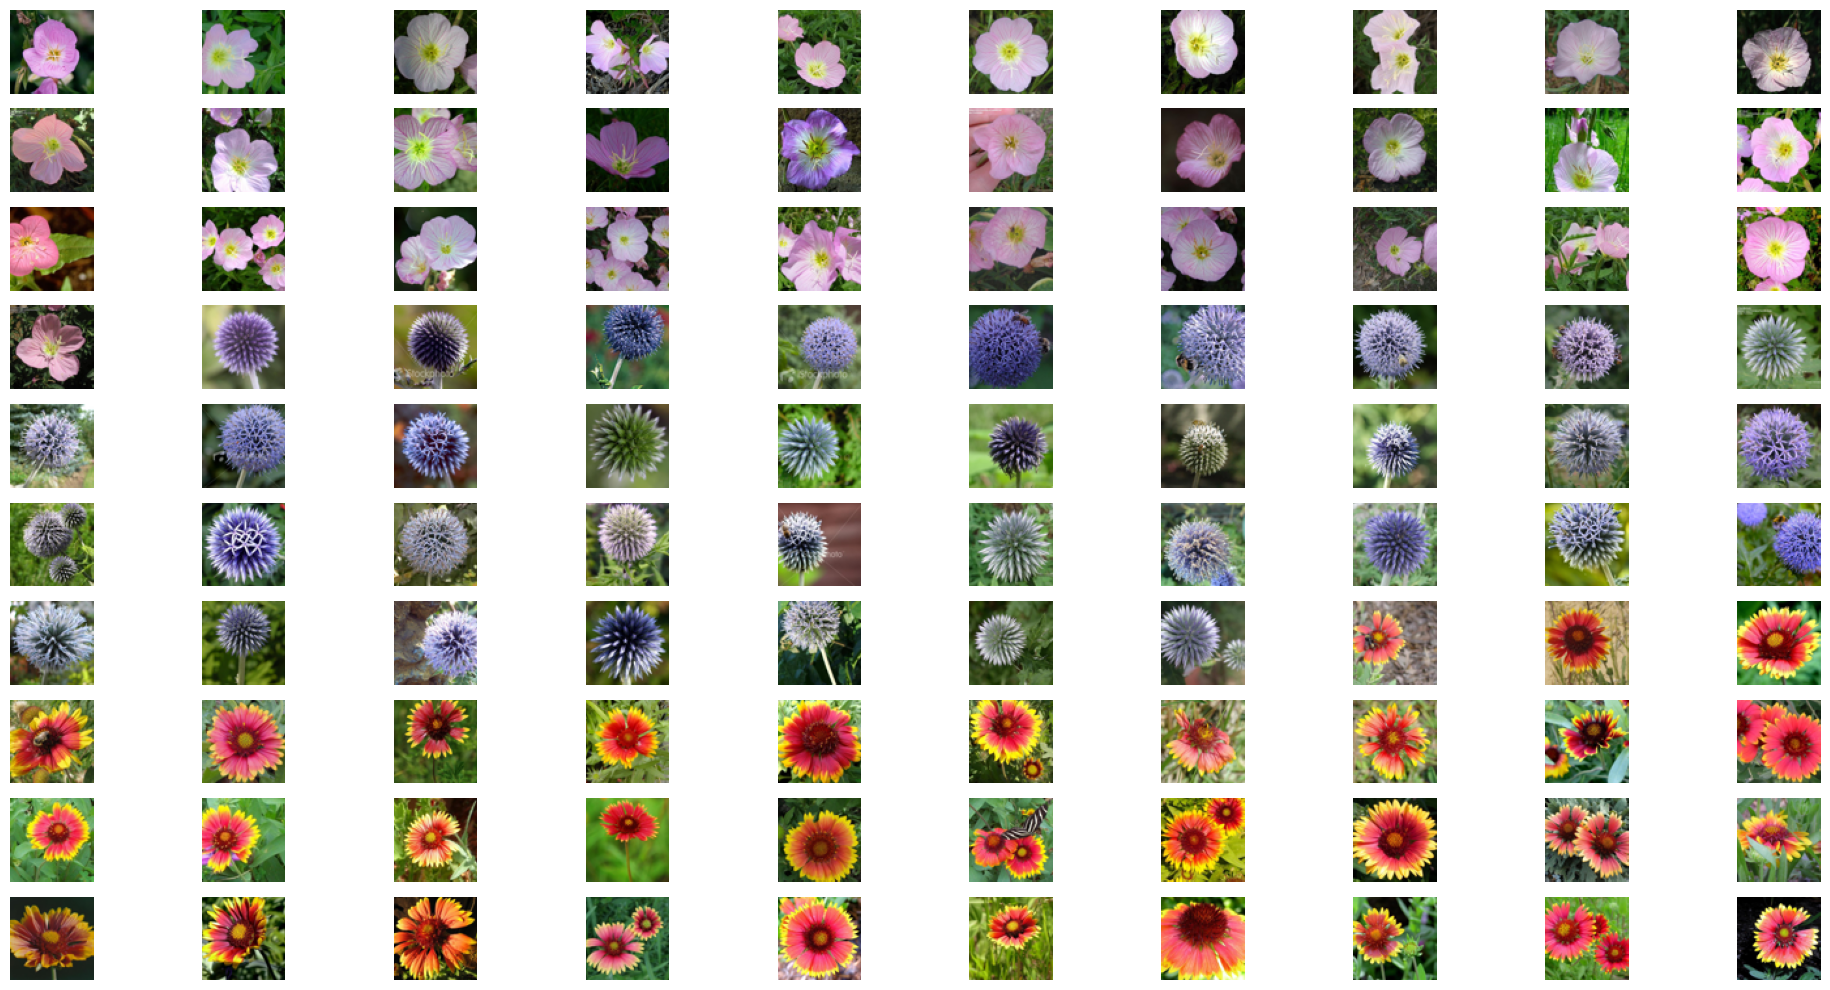

In [3]:
# Visualizar algunas flores.
fig, ejes = plt.subplots(10, 10, figsize=(20, 10))
for eje, imagen in zip(ejes.flat, imagenes[:100]):
    eje.imshow(imagen)
    eje.axis("off")

plt.tight_layout()
plt.show()

In [4]:
np.shape(imagenes)

(100, 64, 64, 3)

### Separar los datos y perturbar las imágenes

**1. Barajar y separar (80 % / 20 %)**

Primero se mezcla el orden de las imágenes al azar y luego se separan:

| Conjunto | Imágenes | Forma |
|---|---|---|
| `entrenamiento` | 80 | $(80,\ 64,\ 64,\ 3)$ |
| `test` | 20 | $(20,\ 64,\ 64,\ 3)$ |

Se baraja porque las flores del conjunto original pueden venir ordenadas por especie.

**2. Perturbar con ruido**, con $\sigma = 0.2$:
$$
\mathbf{Z} \sim \mathcal{N}(\mathbf{0}, I), \qquad \mathbf{Y} = \mathbf{X} + \sigma\,\mathbf{Z}
$$

La función `perturbar` devuelve **dos cosas**: la imagen perturbada $\mathbf{Y}$ y el **ruido estándar** $\mathbf{Z}$, sin multiplicar por $\sigma$. Ese $\mathbf{Z}$ es lo que la red aprenderá a predecir.

**3. Visualizar** una flor original y su versión perturbada. Como el ruido puede sacar valores fuera de $[0, 1]$, se recortan con `np.clip` solo para mostrarla.

Entrenamiento: (80, 64, 64, 3)
Test: (20, 64, 64, 3)


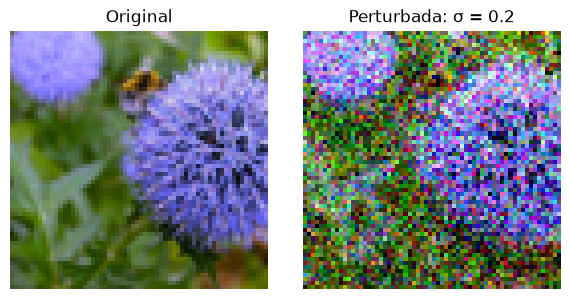

In [5]:
rng = np.random.default_rng(42)

# 1. Barajar y separar las imágenes.
indices = rng.permutation(len(imagenes))
corte = int(0.8 * len(imagenes))

entrenamiento = imagenes[indices[:corte]]
test = imagenes[indices[corte:]]

print("Entrenamiento:", entrenamiento.shape)
print("Test:", test.shape)

# 2. Perturbar todos los píxeles y canales.
sigma = 0.20  # Intensidad del ruido; las imágenes están entre 0 y 1.

def perturbar(X, sigma):
    ruido = rng.normal(size=X.shape).astype("float32")
    return X + sigma * ruido, ruido

entrenamiento_perturbado, ruido_train = perturbar(entrenamiento, sigma)
test_perturbado, ruido_test = perturbar(test, sigma)

# 3. Comparar una imagen antes y después.
i = 0

fig, ejes = plt.subplots(1, 2, figsize=(6, 3))

ejes[0].imshow(entrenamiento[i])
ejes[0].set_title("Original")

# Recortamos a [0, 1] únicamente para visualizar.
ejes[1].imshow(np.clip(entrenamiento_perturbado[i], 0, 1))
ejes[1].set_title(f"Perturbada: σ = {sigma}")

for eje in ejes:
    eje.axis("off")

plt.tight_layout()
plt.show()

### Construir la red neuronal convolucional

La red recibe una flor con ruido $\mathbf{Y}$, de forma $(64, 64, 3)$, y devuelve una predicción del ruido estándar $\mathbf{Z}$, con la **misma forma**:
$$
\hat{\mathbf{Z}} = \text{red}_\theta(\mathbf{Y})
$$

Tiene tres capas convolucionales:

| Capa | Qué hace | Salida |
|---|---|---|
| Entrada | flor con ruido | $(64, 64, 3)$ |
| `Conv2D(32, 3×3, relu)` | mira cada píxel con sus 8 vecinos y extrae 32 "rasgos" | $(64, 64, 32)$ |
| `Conv2D(32, 3×3, relu)` | combina esos rasgos mirando otra vez los vecinos

In [12]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import keras
from keras import layers

keras.utils.set_random_seed(42)

modelo = keras.Sequential([
    keras.Input(shape=entrenamiento.shape[1:]),

    layers.Conv2D(
        32, kernel_size=3, padding="same", activation="relu"
    ),
    layers.Conv2D(
        32, kernel_size=3, padding="same", activation="relu"
    ),

    # Predecir el ruido de los tres canales RGB.
    layers.Conv2D(3, kernel_size=3, padding="same")
])

modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse"
)

modelo.summary()

print("Entrada:", modelo.input_shape)
print("Salida:", modelo.output_shape)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,011 (43.01 KB)

 Trainable params: 11,011 (43.01 KB)

 Non-trainable params: 0 (0.00 B)

Entrada: (None, 64, 64, 3)
Salida: (None, 64, 64, 3)


### Entrenar la red

Se entrena durante 20 **épocas**. En cada época:

1. **Ruido nuevo para el entrenamiento:** se vuelven a perturbar las 80 flores con un ruido distinto,
$$
\mathbf{Y} = \mathbf{X} + \sigma\,\mathbf{Z}, \qquad \sigma = 0.15
$$
2. **Entrenar una época** con `modelo.fit(entradas, ruido_real)`: la red recibe $\mathbf{Y}$ y aprende a predecir $\mathbf{Z}$. Las 80 flores se procesan en lotes de 8, así que en cada época hay $80/8 = 10$ actualizaciones de los pesos.
3. **Evaluar** con `modelo.evaluate` sobre las 20 flores de test, **sin actualizar los pesos**.

En las dos fases se mide el error con el MSE entre el ruido predicho y el real:
$$
\text{MSE} = \big\langle (\hat{\mathbf{Z}} - \mathbf{Z})^2 \big\rangle
$$

**Train vs. test:**
- El **entrenamiento** usa ruido nuevo en cada época, para que la red no memorice ruidos concretos.
- El **test** usa siempre el **mismo** ruido, generado una sola vez antes del ciclo, para que las 20 mediciones sean comparables entre sí.

In [7]:
sigma = 0.15
n_epocas = 20

perdidas_train = []
perdidas_test = []

# El test mantiene el mismo ruido durante toda la evaluación.
test_perturbado, ruido_test = perturbar(test, sigma)

for epoca in range(n_epocas):
    # Entrenamiento con ruido nuevo.
    entradas, ruido_real = perturbar(entrenamiento, sigma)

    historia = modelo.fit(
        entradas,
        ruido_real,
        epochs=1,
        batch_size=8,
        shuffle=True,
        verbose=0
    )

    mse_train = historia.history["loss"][0]

    # Evaluación: los pesos permanecen fijos.
    mse_test = modelo.evaluate(
        test_perturbado,
        ruido_test,
        batch_size=8,
        verbose=0
    )

    perdidas_train.append(mse_train)
    perdidas_test.append(mse_test)

    print(
        f"Época {epoca + 1:02d}/{n_epocas} | "
        f"Train: {mse_train:.4f} | Test: {mse_test:.4f}"
    )

# Graficar ambas curvas.
epocas = range(1, n_epocas + 1)


Época 01/20 | Train: 0.9639 | Test: 0.9162
Época 02/20 | Train: 0.8599 | Test: 0.7756
Época 03/20 | Train: 0.7070 | Test: 0.6205
Época 04/20 | Train: 0.5554 | Test: 0.4757
Época 05/20 | Train: 0.4205 | Test: 0.3635
Época 06/20 | Train: 0.3301 | Test: 0.2962
Época 07/20 | Train: 0.2777 | Test: 0.2575
Época 08/20 | Train: 0.2498 | Test: 0.2353
Época 09/20 | Train: 0.2329 | Test: 0.2240
Época 10/20 | Train: 0.2245 | Test: 0.2179
Época 11/20 | Train: 0.2196 | Test: 0.2135
Época 12/20 | Train: 0.2165 | Test: 0.2092
Época 13/20 | Train: 0.2125 | Test: 0.2066
Época 14/20 | Train: 0.2104 | Test: 0.2052
Época 15/20 | Train: 0.2089 | Test: 0.2046
Época 16/20 | Train: 0.2084 | Test: 0.2024
Época 17/20 | Train: 0.2077 | Test: 0.2024
Época 18/20 | Train: 0.2059 | Test: 0.2017
Época 19/20 | Train: 0.2055 | Test: 0.2009
Época 20/20 | Train: 0.2049 | Test: 0.2038


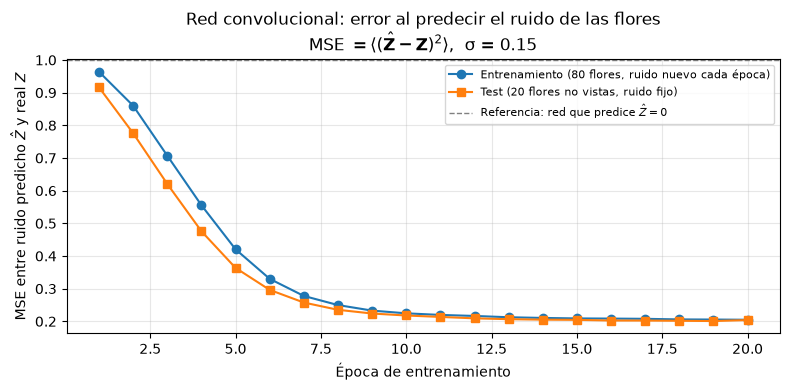

In [9]:
plt.figure(figsize=(8, 4))
plt.plot(epocas, perdidas_train, "o-", label="Entrenamiento (80 flores, ruido nuevo cada época)")
plt.plot(epocas, perdidas_test, "s-", label="Test (20 flores no vistas, ruido fijo)")

plt.axhline(1.0, color="gray", linestyle="--", linewidth=1,
            label=r"Referencia: red que predice $\hat{Z}=0$")

plt.title("Red convolucional: error al predecir el ruido de las flores\n"
          r"MSE $= \langle(\hat{\mathbf{Z}} - \mathbf{Z})^2\rangle$"
          f",  σ = {sigma}")
plt.xlabel("Época de entrenamiento")
plt.ylabel(r"MSE entre ruido predicho $\hat{Z}$ y real $Z$")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Limpiar las flores de test con la red

1. **Predecir el ruido** de las flores de test con la red entrenada:
$$
\hat{\mathbf{Z}} = \text{red}_\theta(\mathbf{Y})
$$
2. **Restarlo** para recuperar la flor limpia:
$$
\mathbf{X}_{\text{recuperada}} = \mathbf{Y} - \sigma\,\hat{\mathbf{Z}}
$$
Es el mismo salto de las partes anteriores, escrito con el ruido en vez del campo: como $\mathbf{S} = -\hat{\mathbf{Z}}/\sigma$, se tiene $\mathbf{Y} + \sigma^2\mathbf{S} = \mathbf{Y} - \sigma\hat{\mathbf{Z}}$.

3. **Medir el error** respecto a las flores originales:
   - **MSE antes:** entre la flor con ruido y la original. Debe ser $\approx \sigma^2 = 0.0225$.
   - **MSE después:** entre la flor recuperada y la original.

4. **Visualizar** una flor: original, perturbada y recuperada.

MSE antes:   0.022501
MSE después: 0.004586


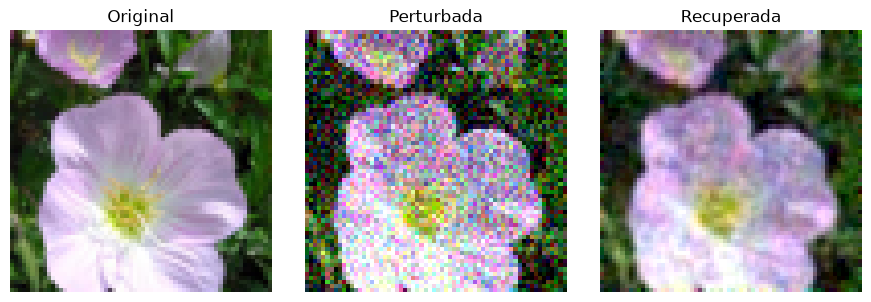

In [10]:
# Predecir el ruido y restarlo.
ruido_predicho = modelo.predict(
    test_perturbado, batch_size=8, verbose=0
)

sigma=0.15
recuperadas = test_perturbado - sigma * ruido_predicho

# Comparar el error respecto a las imágenes originales.
mse_antes = np.mean((test_perturbado - test)**2)
mse_despues = np.mean((recuperadas - test)**2)

print(f"MSE antes:   {mse_antes:.6f}")
print(f"MSE después: {mse_despues:.6f}")

# Visualizar una flor.
i = 3
fig, ejes = plt.subplots(1, 3, figsize=(9, 3))

comparacion = [
    (test[i], "Original"),
    (test_perturbado[i], "Perturbada"),
    (recuperadas[i], "Recuperada")
]

for eje, (imagen, titulo) in zip(ejes, comparacion):
    eje.imshow(np.clip(imagen, 0, 1))  # Recorte solo para mostrar.
    eje.set_title(titulo)
    eje.axis("off")

plt.tight_layout()
plt.show()

### Generar flores nuevas con Langevin

**Objetivo:** crear 9 imágenes nuevas que parezcan flores, partiendo de píxeles al azar y sin usar ninguna flor real.

**Punto de partida:** 9 imágenes de $64 \times 64 \times 3$ con valores al azar entre 0 y 1 (ruido uniforme).

En cada uno de los 5000 pasos se hace lo siguiente:

**a) Preguntarle a la red qué ruido ve.** Se le pasa la imagen actual $\mathbf{Y}_n$ y la red responde, para cada píxel y canal, cuánto ruido cree que tiene:
$$
\hat{\mathbf{Z}} = \text{red}(\mathbf{Y}_n)
$$

**b) Convertir esa respuesta en una flecha (el score).** Langevin no necesita saber "cuánto ruido hay", sino **hacia dónde mover** cada píxel para que la imagen se parezca más a una flor. Esa dirección es la **contraria al ruido**: si la red dice que un píxel tiene ruido hacia arriba, hay que moverlo hacia abajo. Por eso:
$$
\mathbf{S} = -\frac{\hat{\mathbf{Z}}}{\sigma}
$$
El signo menos invierte la dirección, y dividir entre $\sigma$ pone la flecha en la escala correcta. (Sale de $\mathbf{S} = -\boldsymbol{\epsilon}/\sigma^2$ con $\boldsymbol{\epsilon} = \sigma\hat{\mathbf{Z}}$.)



**c) Mover la imagen un poquito en esa dirección, más una pequeña sacudida al azar:**
$$
\mathbf{Y}_{n+1} = \mathbf{Y}_n + \underbrace{h\,\mathbf{S}}_{\text{empujón hacia "flor"}} + \underbrace{\sqrt{2h}\;\boldsymbol{\xi}_n}_{\text{sacudida al azar}}, \qquad \boldsymbol{\xi}_n \sim \mathcal{N}(\mathbf{0}, I)
$$
Aquí $\boldsymbol{\xi}_n$ es un ruido **nuevo** que se genera en cada paso. No tiene nada que ver con el $\hat{\mathbf{Z}}$

In [14]:
import torch

n_imagenes = 9
n_pasos = 5000
rng_generacion = np.random.default_rng(123)

# Paso pequeño de Langevin.
h = np.float32(0.005 * sigma**2)
amplitud = np.float32(np.sqrt(2 * h))

# Inicialización independiente de las flores originales.
forma = tuple(modelo.input_shape[1:])
generadas = rng_generacion.uniform(
    0, 1, size=(n_imagenes, *forma)
).astype("float32")

# Guardar la evolución de la primera imagen.
evolucion = {0: generadas[0].copy()}
guardar_en = {50, 100, 250, n_pasos}

# Inferencia con tu backend Torch: los pesos permanecen fijos.
with torch.no_grad():
    for paso in range(1, n_pasos + 1):

        # La red predice epsilon, no sigma * epsilon.
        ruido_predicho = keras.ops.convert_to_numpy(
            modelo(generadas, training=False)
        )

        score = -ruido_predicho / sigma

        # Ruido nuevo para la dinámica de Langevin.
        z = rng_generacion.normal(
            size=generadas.shape
        ).astype("float32")

        generadas = generadas + h * score + amplitud * z

        # Mantener los valores sin recortar durante la dinámica.
        if paso in guardar_en:
            evolucion[paso] = generadas[0].copy()

        if paso % 100 == 0:
            if not np.isfinite(generadas).all():
                raise FloatingPointError(
                    "La dinámica diverge. Reduce el valor de h."
                )
            print(f"Paso {paso}/{n_pasos}")



Paso 100/5000
Paso 200/5000
Paso 300/5000
Paso 400/5000
Paso 500/5000
Paso 600/5000
Paso 700/5000
Paso 800/5000
Paso 900/5000
Paso 1000/5000
Paso 1100/5000
Paso 1200/5000
Paso 1300/5000
Paso 1400/5000
Paso 1500/5000
Paso 1600/5000
Paso 1700/5000
Paso 1800/5000
Paso 1900/5000
Paso 2000/5000
Paso 2100/5000
Paso 2200/5000
Paso 2300/5000
Paso 2400/5000
Paso 2500/5000
Paso 2600/5000
Paso 2700/5000
Paso 2800/5000
Paso 2900/5000
Paso 3000/5000
Paso 3100/5000
Paso 3200/5000
Paso 3300/5000
Paso 3400/5000
Paso 3500/5000
Paso 3600/5000
Paso 3700/5000
Paso 3800/5000
Paso 3900/5000
Paso 4000/5000
Paso 4100/5000
Paso 4200/5000
Paso 4300/5000
Paso 4400/5000
Paso 4500/5000
Paso 4600/5000
Paso 4700/5000
Paso 4800/5000
Paso 4900/5000
Paso 5000/5000


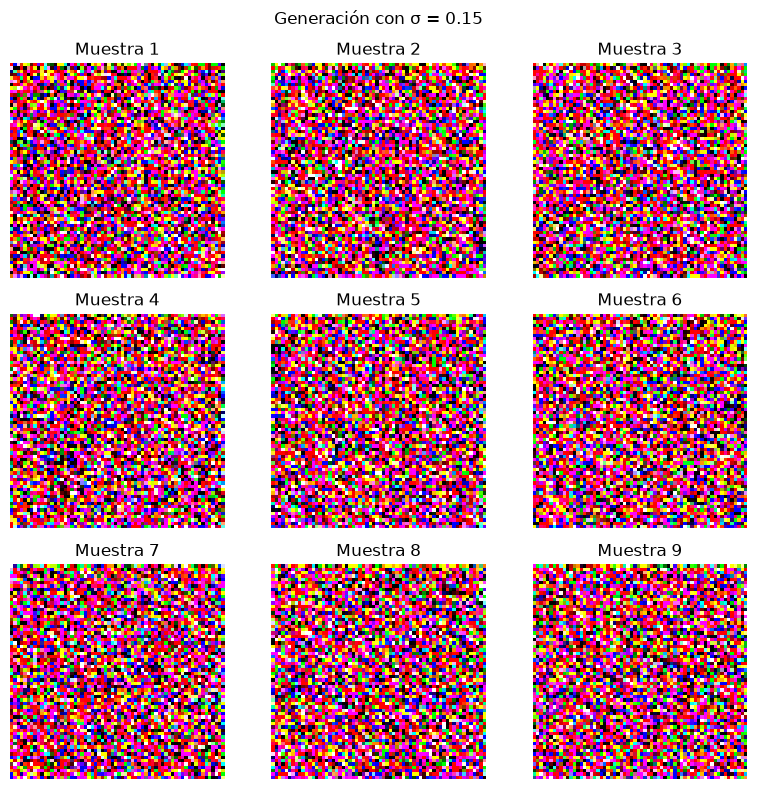

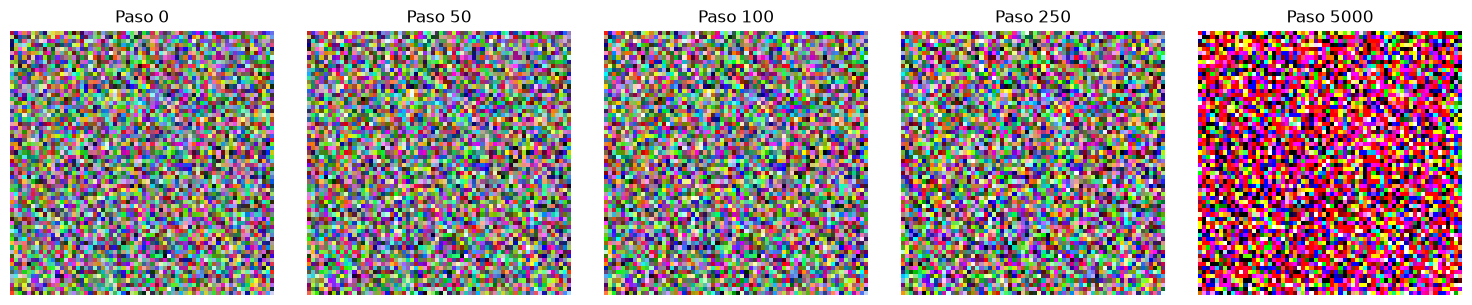

In [16]:
# Mostrar las nueve imágenes finales.
fig, ejes = plt.subplots(3, 3, figsize=(8, 8))

for i, eje in enumerate(ejes.flat):
    eje.imshow(np.clip(generadas[i], 0, 1))
    eje.set_title(f"Muestra {i + 1}")
    eje.axis("off")

fig.suptitle(f"Generación con σ = {float(sigma):.2f}")
plt.tight_layout()
plt.show()

# Mostrar cómo evolucionó la primera imagen.
fig, ejes = plt.subplots(
    1, len(evolucion), figsize=(3 * len(evolucion), 3)
)

for eje, (paso, imagen) in zip(ejes, evolucion.items()):
    eje.imshow(np.clip(imagen, 0, 1))
    eje.set_title(f"Paso {paso}")
    eje.axis("off")

plt.tight_layout()
plt.show()


**Análisis de las imágenes generadas**

Se observa que la generación no funcionó. Las 9 muestras son píxeles de colores muy saturados, sin formas reconocibles, y la evolución de la primera imagen muestra que los colores se vuelven más extremos con los pasos en lugar de formar una flor. Los colores puros aparecen porque muchos valores se salieron del rango $[0, 1]$ y quedaron recortados en 0 o 1. Esto ocurre porque la red solo aprendió a reconocer el ruido en imágenes cercanas a flores reales ($\mathbf{x} + 0.15\,\mathbf{Z}$), mientras que Langevin parte de ruido uniforme, una zona donde las predicciones de la red no son confiables. 

# Tarea: generar flores con una U-Net

## Motivación

La red convolucional anterior aprendió a **limpiar** flores con ruido (el error bajó a la quinta parte), pero **no logró generar** flores desde cero: las muestras de Langevin terminaron siendo píxeles de colores saturados. Una de las causas es que cada píxel solo "veía" una zona de $7 \times 7$ a su alrededor, insuficiente para organizar formas grandes como pétalos o una flor completa.

La tarea es reemplazar esa red por una **U-Net**, la arquitectura que usan los modelos de difusión, manteniendo igual el resto del procedimiento: perturbar las imágenes, entrenar la red para predecir el ruido $\mathbf{Z}$ y generar con Langevin usando el score $\mathbf{S} = -\hat{\mathbf{Z}}/\sigma$.

## ¿Qué es una U-Net?

Es una red con forma de **U**: primero **reduce** la imagen para ver zonas grandes y después la **vuelve a agrandar** para predecir el ruido de cada píxel. Cada nivel de bajada se conecta con su nivel de subida mediante un **puente**.

```
 entrada 64×64×3                                     salida 64×64×3
      │                                                    ▲
  conv 64×64×32 ─────────────── puente ──────────► conv 64×64×32
      │ reducir                                            ▲ agrandar
  conv 32×32×64 ──────── puente ────────► conv 32×32×64
      │ reducir                                  ▲ agrandar
      └─────────────► conv 16×16×128 ────────────┘
                         (fondo)
```

| Parte | Qué hace | Para qué sirve |
|---|---|---|
| **Bajada** (*encoder*) | convoluciones y reducción a la mitad: $64 \to 32 \to 16$ | ver zonas cada vez más grandes de la imagen |
| **Fondo** (*bottleneck*) | convoluciones sobre la imagen de $16 \times 16$ | captar la estructura general de la flor |
| **Subida** (*decoder*) | duplicar el tamaño y convoluciones: $16 \to 32 \to 64$ | volver al tamaño original para predecir el ruido píxel por píxel |
|

Al reducir la imagen, cada filtro de $3 \times 3$ cubre una zona mayor de la imagen original. En el nivel de $16 \times 16$, un filtro abarca $12 \times 12$ píxeles originales, y con varias capas la zona que influye en cada predicción supera los $40 \times 40$ píxeles: casi toda la flor de $64 \times 64$.

| | Red anterior | U-Net |
|---|---|---|
| Zona que ve cada píxel | $7 \times 7$ | más de $40 \times 40$ |
| ¿Puede organizar formas grandes? | no | sí |
| ¿Conserva los detalles finos? | sí | sí, gracias a los puentes |

Así la red puede reconocer el ruido teniendo en cuenta la forma completa de la flor, no solo los píxeles vecinos.

## Implementación

Como los puentes requieren reutilizar salidas de capas anteriores, la red se construye con la **API funcional** de Keras (`keras.Model(entrada, salida)`) en lugar de `keras.Sequential`. Las capas nuevas son:

- `MaxPooling2D(2)`: reduce la imagen a la mitad, tomando el valor máximo de cada bloque de $2 \times 2$.
- `UpSampling2D(2)`: duplica el tamaño de la imagen, repitiendo cada píxel en un bloque de $2 \times 2$.
- `Concatenate()`: une dos pilas de mapas del mismo tamaño, sumando sus canales (por ejemplo, $64 + 64 = 128$).

La entrada y la salida deben tener la misma forma, $(64, 64, 3)$, y la última capa no lleva activación, porque el ruido predicho puede ser negativo.

### Construir la U-Net

Se define un **bloque convolucional**: dos capas `Conv2D` de $3 \times 3$ con activación `relu`. La U-Net usa este bloque en todos los niveles:

| Nivel | Operación | Forma de salida |
|---|---|---|
| Entrada | flor con ruido | $(64, 64, 3)$ |
| Bajada 1 | bloque con 32 filtros → **se guarda `c1`** | $(64, 64, 32)$ |
| | `MaxPooling2D`: reduce a la mitad | $(32, 32, 32)$ |
| Bajada 2 | bloque con 64 filtros → **se guarda `c2`** | $(32, 32, 64)$ |
| | `MaxPooling2D` | $(16, 16, 64)$ |
| Fondo | bloque con 128 filtros | $(16, 16, 128)$ |
| Subida 2 | `UpSampling2D`: duplica el tamaño | $(32, 32, 128)$ |
| | puente: se une con `c2` ($128 + 64$ canales) | $(32, 32, 192)$ |
| | bloque con 64 filtros | $(32, 32, 64)$ |
| Subida 1 | `UpSampling2D` | $(64, 64, 64)$ |
| | puente: se une con `c1` ($64 + 32$ canales) | $(64, 64, 96)$ |
| | bloque con 32 filtros | $(64, 64, 32)$ |
| Salida | `Conv2D(3)` sin activación: ruido predicho $\hat{\mathbf{Z}}$ | $(64, 64, 3)$ |

Se compila igual que la red anterior: pérdida MSE entre el ruido predicho y el real, y optimizador Adam con tasa de aprendizaje $10^{-3}$.

In [17]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import torch
import keras
from keras import layers

keras.utils.set_random_seed(42)


def bloque_conv(x, filtros):
    """Dos convoluciones 3×3 con relu, conservando el tamaño de la imagen."""
    x = layers.Conv2D(filtros, 3, padding="same", activation="relu")(x)
    x = layers.Conv2D(filtros, 3, padding="same", activation="relu")(x)
    return x


# Entrada: flor con ruido (64, 64, 3)
entrada = keras.Input(shape=entrenamiento.shape[1:])

# --- Bajada (encoder) ---
c1 = bloque_conv(entrada, 32)            # (64, 64, 32)  → se guarda para el puente
p1 = layers.MaxPooling2D(2)(c1)          # (32, 32, 32)

c2 = bloque_conv(p1, 64)                 # (32, 32, 64)  → se guarda para el puente
p2 = layers.MaxPooling2D(2)(c2)          # (16, 16, 64)

# --- Fondo (bottleneck) ---
b = bloque_conv(p2, 128)                 # (16, 16, 128)

# --- Subida (decoder) ---
u2 = layers.UpSampling2D(2)(b)           # (32, 32, 128)
u2 = layers.Concatenate()([u2, c2])      # (32, 32, 192)  puente con c2
u2 = bloque_conv(u2, 64)                 # (32, 32, 64)

u1 = layers.UpSampling2D(2)(u2)          # (64, 64, 64)
u1 = layers.Concatenate()([u1, c1])      # (64, 64, 96)   puente con c1
u1 = bloque_conv(u1, 32)                 # (64, 64, 32)

# --- Salida: ruido predicho para R, G, B (sin activación) ---
salida = layers.Conv2D(3, 3, padding="same")(u1)   # (64, 64, 3)

modelo = keras.Model(entrada, salida, name="unet")

modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse"
)

modelo.summary()
print("Entrada:", modelo.input_shape)
print("Salida:", modelo.output_shape)

Model: "unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 64, 64,    │        896 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 64, 64,    │      9,248 │ conv2d_6[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 32, 32,    │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 32, 32,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 32, 32,    │     36,928 │ conv2d_8[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 16, 16,    │          0 │ conv2d_9[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 16, 16,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 16, 16,    │    147,584 │ conv2d_10[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 32, 32,    │          0 │ conv2d_11[0][0]   │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32, 32,    │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 192)              │            │ conv2d_9[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 32, 32,    │    110,656 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 32, 32,    │     36,928 │ conv2d_12[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 64, 64,    │          0 │ conv2d_13[0][0]   │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 64, 64,    │          0 │ up_sampling2d_1[… │
│ (Concatenate)       │ 96)               │            │ conv2d_7[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 64, 64,    │     27,680 │ concatenate_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 64, 64,    │      9,248 │ conv2d_14[0][0] 

 Total params: 472,387 (1.80 MB)

 Trainable params: 472,387 (1.80 MB)

 Non-trainable params: 0 (0.00 B)

Entrada: (None, 64, 64, 3)
Salida: (None, 64, 64, 3)


### Entrenar la U-Net y evaluarla en cada época

En cada época se hacen dos cosas:
1. **Entrenar:** la red ajusta sus pesos con las 80 flores de entrenamiento.
2. **Evaluar:** se mide el error con las 20 flores de test, **sin ajustar los pesos**, para comprobar que lo aprendido también funciona con flores que la red nunca vio.

La red anterior se entrenó solo con $\sigma = 0.15$, es decir, solo vio imágenes **muy cercanas** a flores reales. Al generar desde ruido puro, la imagen empezaba lejos de esa zona y la red no sabía orientarse.

Por eso la U-Net se entrena con **varios niveles de ruido**:
$$
\sigma \in \{0.5,\ 0.3,\ 0.2,\ 0.15,\ 0.1,\ 0.05\}
$$
En cada época, a cada flor se le asigna un $\sigma$ al azar de esa lista:
$$
\mathbf{Y} = \mathbf{X} + \sigma\,\mathbf{Z}, \qquad \mathbf{Z} \sim \mathcal{N}(\mathbf{0}, I)
$$
La red sigue aprendiendo a predecir el ruido estándar $\mathbf{Z}$. No se le dice qué $\sigma$ se usó: tiene que deducirlo viendo cuánto ruido tiene la imagen.

- Con $\sigma$ **grande**, aprende a orientarse

Época 01/40 | Train: 0.9740 | Test (σ=0.15): 0.9396
Época 02/40 | Train: 0.8503 | Test (σ=0.15): 0.7800
Época 03/40 | Train: 0.6335 | Test (σ=0.15): 0.5990
Época 04/40 | Train: 0.5318 | Test (σ=0.15): 0.4499
Época 05/40 | Train: 0.4503 | Test (σ=0.15): 0.3980
Época 06/40 | Train: 0.4292 | Test (σ=0.15): 0.3189
Época 07/40 | Train: 0.3809 | Test (σ=0.15): 0.2936
Época 08/40 | Train: 0.3449 | Test (σ=0.15): 0.3134
Época 09/40 | Train: 0.3430 | Test (σ=0.15): 0.2727
Época 10/40 | Train: 0.3141 | Test (σ=0.15): 0.2413
Época 11/40 | Train: 0.2790 | Test (σ=0.15): 0.2238
Época 12/40 | Train: 0.2798 | Test (σ=0.15): 0.2152
Época 13/40 | Train: 0.2611 | Test (σ=0.15): 0.2152
Época 14/40 | Train: 0.2553 | Test (σ=0.15): 0.2132
Época 15/40 | Train: 0.2626 | Test (σ=0.15): 0.2101
Época 16/40 | Train: 0.2718 | Test (σ=0.15): 0.2105
Época 17/40 | Train: 0.2583 | Test (σ=0.15): 0.2110
Época 18/40 | Train: 0.2618 | Test (σ=0.15): 0.2137
Época 19/40 | Train: 0.2696 | Test (σ=0.15): 0.2192
Época 20/40 

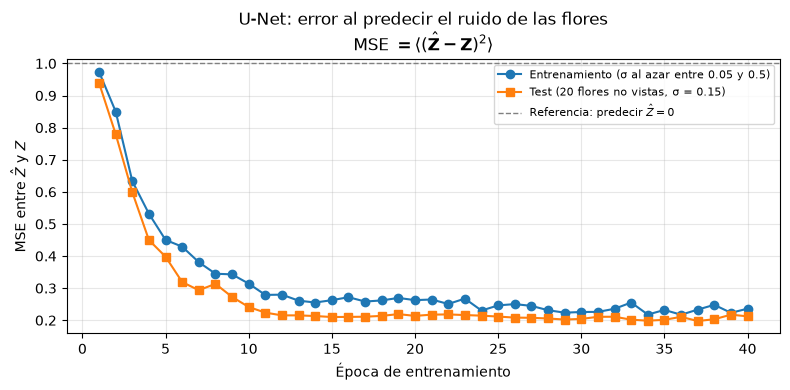

In [18]:
# Niveles de ruido para el entrenamiento
sigmas = np.array([0.5, 0.3, 0.2, 0.15, 0.1, 0.05], dtype="float32")

def perturbar_varios_sigma(X):
    """Asigna a cada imagen un sigma al azar y devuelve (Y, Z)."""
    s = rng.choice(sigmas, size=(len(X), 1, 1, 1)).astype("float32")
    Z = rng.normal(size=X.shape).astype("float32")
    return X + s * Z, Z

# Test: siempre con sigma = 0.15 y el mismo ruido, para comparar con la red anterior
sigma_test = 0.15
test_perturbado, ruido_test = perturbar(test, sigma_test)

n_epocas = 40
perdidas_train = []
perdidas_test = []

for epoca in range(n_epocas):
    # Ruido nuevo, con un sigma distinto para cada flor
    entradas, ruido_real = perturbar_varios_sigma(entrenamiento)

    historia = modelo.fit(
        entradas, ruido_real,
        epochs=1, batch_size=8, shuffle=True, verbose=0
    )
    mse_train = historia.history["loss"][0]

    mse_test = modelo.evaluate(test_perturbado, ruido_test, batch_size=8, verbose=0)

    perdidas_train.append(mse_train)
    perdidas_test.append(mse_test)

    print(f"Época {epoca + 1:02d}/{n_epocas} | Train: {mse_train:.4f} | Test (σ=0.15): {mse_test:.4f}")

# Curvas de pérdida
epocas = range(1, n_epocas + 1)
plt.figure(figsize=(8, 4))
plt.plot(epocas, perdidas_train, "o-", label="Entrenamiento (σ al azar entre 0.05 y 0.5)")
plt.plot(epocas, perdidas_test, "s-", label="Test (20 flores no vistas, σ = 0.15)")
plt.axhline(1.0, color="gray", linestyle="--", linewidth=1, label=r"Referencia: predecir $\hat{Z}=0$")
plt.title("U-Net: error al predecir el ruido de las flores\n"
          r"MSE $= \langle(\hat{\mathbf{Z}} - \mathbf{Z})^2\rangle$")
plt.xlabel("Época de entrenamiento")
plt.ylabel(r"MSE entre $\hat{Z}$ y $Z$")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Generar flores con Langevin por niveles de ruido (*annealed Langevin*)

En el intento anterior, Langevin partía de ruido puro con un solo $\sigma = 0.15$, y la red no sabía orientarse tan lejos de las flores. Ahora se aprovecha que la U-Net conoce varios niveles de ruido, y la generación se hace **por etapas, de mayor a menor $\sigma$**:

**1. Inicio:** la imagen promedio de las flores de entrenamiento más ruido fuerte:
$$
\mathbf{Y}_0 = \boldsymbol{\mu}_{\text{flores}} + \sigma_{\max}\,\mathbf{Z}, \qquad \sigma_{\max} = 0.5
$$

**2. Para cada nivel** $\sigma \in \{0.5,\ 0.3,\ 0.2,\ 0.15,\ 0.1,\ 0.05\}$, se repiten 150 pasos de Langevin:
$$
\mathbf{S} = -\frac{\hat{\mathbf{Z}}}{\sigma}, \qquad

Nivel σ = 0.5 terminado (h = 0.01250)
Nivel σ = 0.3 terminado (h = 0.00450)
Nivel σ = 0.2 terminado (h = 0.00200)
Nivel σ = 0.15 terminado (h = 0.00112)
Nivel σ = 0.1 terminado (h = 0.00050)
Nivel σ = 0.05 terminado (h = 0.00013)


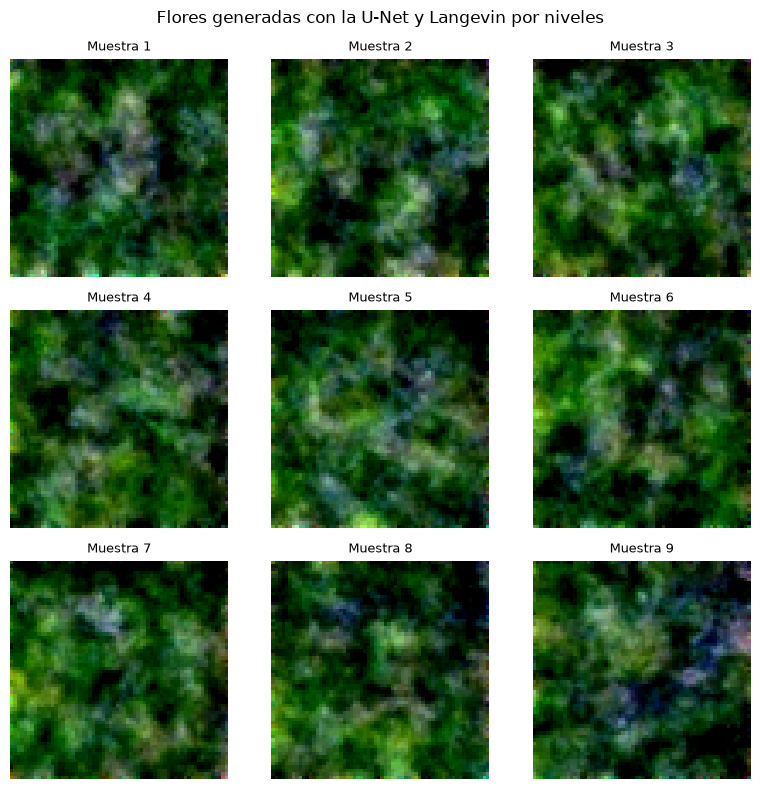

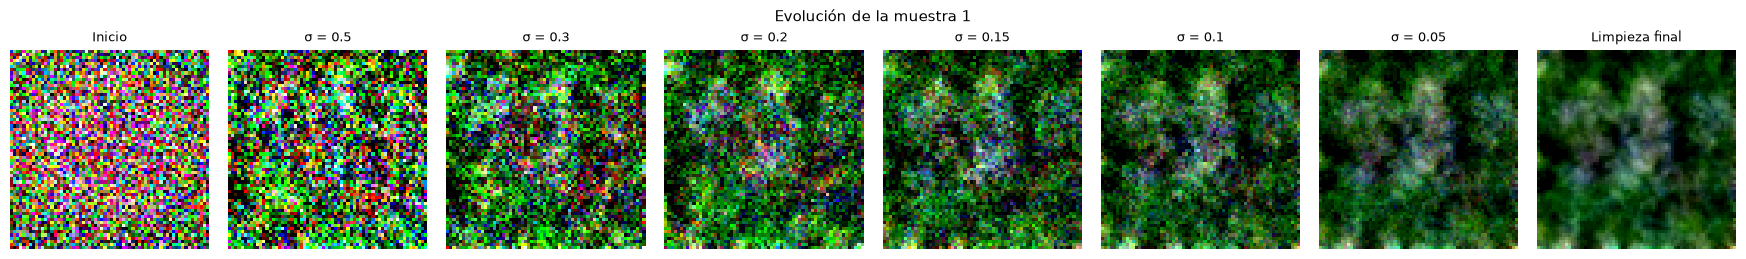

In [19]:
n_imagenes = 9
pasos_por_nivel = 150
c = 0.05                                          # h = c · σ²
sigmas_gen = [0.5, 0.3, 0.2, 0.15, 0.1, 0.05]     # de mayor a menor
rng_generacion = np.random.default_rng(123)

# 1. Inicio: flor promedio + ruido fuerte
media_flores = entrenamiento.mean(axis=0)
forma = entrenamiento.shape[1:]
Y = (media_flores + sigmas_gen[0] * rng_generacion.normal(size=(n_imagenes, *forma))).astype("float32")

evolucion = {"Inicio": Y[0].copy()}

with torch.no_grad():
    # 2. Langevin por niveles
    for sigma_actual in sigmas_gen:
        h = np.float32(c * sigma_actual**2)
        amplitud = np.float32(np.sqrt(2 * h))

        for k in range(pasos_por_nivel):
            Z_pred = keras.ops.convert_to_numpy(modelo(Y, training=False))
            score = -Z_pred / sigma_actual
            xi = rng_generacion.normal(size=Y.shape).astype("float32")
            Y = Y + h * score + amplitud * xi

        if not np.isfinite(Y).all():
            raise FloatingPointError("La dinámica diverge. Reduce el valor de c.")

        evolucion[f"σ = {sigma_actual}"] = Y[0].copy()
        print(f"Nivel σ = {sigma_actual} terminado (h = {h:.5f})")

    # 3. Limpieza final
    Z_pred = keras.ops.convert_to_numpy(modelo(Y, training=False))
    Y_final = Y - sigmas_gen[-1] * Z_pred

evolucion["Limpieza final"] = Y_final[0].copy()

# --- Las 9 flores generadas ---
fig, ejes = plt.subplots(3, 3, figsize=(8, 8))
for i, eje in enumerate(ejes.flat):
    eje.imshow(np.clip(Y_final[i], 0, 1))
    eje.set_title(f"Muestra {i + 1}", fontsize=9)
    eje.axis("off")
fig.suptitle("Flores generadas con la U-Net y Langevin por niveles", fontsize=12)
plt.tight_layout()
plt.show()

# --- Evolución de la primera muestra ---
fig, ejes = plt.subplots(1, len(evolucion), figsize=(2.2 * len(evolucion), 2.6))
for eje, (etapa, imagen) in zip(ejes, evolucion.items()):
    eje.imshow(np.clip(imagen, 0, 1))
    eje.set_title(etapa, fontsize=9)
    eje.axis("off")
fig.suptitle("Evolución de la muestra 1", fontsize=11)
plt.tight_layout()
plt.show()



Se puede observar que las nueve muestras ya no son ruido de colores saturados como en el intento anterior, ahora son imágenes suaves, con zonas de distintos tonos de verde, sombras oscuras y manchas más claras de color blanco. Se parecen a una fotografía de follaje con pequeñas flores, que es justamente el aspecto de fondo de muchas imágenes del conjunto Oxford Flowers. Además, las muestras son distintas entre sí, lo que indica que Langevin genera variedad y no una sola imagen promedio, como ocurría con el modelo lineal de los perros. Sin embargo, todavía no aparece una flor completa y bien definida en el centro de la imagen: la red aprendió los colores y las texturas típicas de las fotos, pero no la forma de una flor.

La evolución de la muestra 1 muestra cómo funciona Langevin por niveles. Al inicio la imagen es ruido puro. Con $\sigma = 0.5$ y $\sigma = 0.3$ empiezan a dominar los verdes y aparecen zonas oscuras y claras. Entre $\sigma = 0.2$ y $\sigma = 0.1$ esas zonas se organizan en manchas más definidas, aunque todavía con grano. Con $\sigma = 0.05$ la imagen ya es suave, y la limpieza final elimina el ruido restante. Cada nivel ed ruido aporta algo. Podría decirse que los niveles altos fijan la composición general y los bajos pulen los detalles.

